# Session 13 — Reversible Training of a 20M-Parameter LLM

**Assignment (lesson §18).** Train a 20M LLM for 50M tokens. Train again with reversibility and report which variant
worked. Train again with reversibility at the maximum batch size. Report final loss, speed (tokens/s), peak memory and
other findings.

**Why this matters (lesson §16–17).** Every parallelism in Session 13 (tensor, sequence, pipeline, context) divides the
*activations* across more GPUs. A reversible network removes most of them instead: the forward pass keeps only the
states at the top of the stack, and the backward pass rebuilds each layer's input from its output by running the
layer's update rule backwards. Activation memory then stops growing with depth, at the cost of one extra forward
evaluation of each block.

**What this notebook does, top to bottom**

| § | Content | Assignment task |
|---|---|---|
| 0 | setup, the model/training code (`revllm.py`), a 20-second smoke test | |
| 1 | data: 50M TinyStories tokens, vocabulary remapped to 8,192 ids | |
| 2 | the 20.8M-parameter model, parameters counted by hand | |
| 3 | reversible residual streams from first principles: Euler, midpoint, leapfrog, Hamiltonian; the two starting states; the backward recursion | |
| 4 | correctness: gradients vs ordinary autograd (fp64), reconstruction error, and where it breaks (dropout, bf16 stream) | |
| 5 | **baseline, 50M tokens, B = 64 × 512** | **Task 1** |
| 6 | screening of 8 reversible variants at 5M tokens | **Task 2** (which variant) |
| 7 | **the best reversible variant, 50M tokens, same batch** | **Task 2** |
| 8 | memory anatomy: memory vs batch, memory vs depth, the logits trap | findings |
| 9 | **largest batch that fits, baseline vs reversible; 50M tokens at the reversible maximum** | **Task 3** |
| 10 | all results in one table | report |

Hardware: one Colab **L4** (24 GB, Ada, bf16). Expected run time ≈ 60–75 min. Every prediction is written before the
cell that tests it; the *Observations* cells are filled from the real outputs afterwards.

## 0. Setup

`PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True` lets PyTorch's caching allocator grow one memory segment instead of
leaving holes between fixed-size blocks. It must be set before the first CUDA call. It matters in §9, where batches are
pushed to the edge of the card and fragmentation alone could cause an out-of-memory error.

Two words used throughout:
* **peak memory** = `torch.cuda.max_memory_allocated()`: the largest number of bytes held by live tensors at any moment of
  the run. (The card also holds the CUDA context and the allocator's cache, so `nvidia-smi` shows more.)
* **GiB** = $2^{30}$ bytes = 1.074 GB. The L4 has 24 GB = 22.5 GiB, of which about 22 GiB can hold tensors.

In [1]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"   # must be set before torch touches the GPU
!pip -q install tiktoken

import gc, json, math, time, importlib
from dataclasses import replace
import numpy as np
import torch
import matplotlib.pyplot as plt

assert torch.cuda.is_available(), "this notebook needs a GPU runtime (L4 recommended)"
props = torch.cuda.get_device_properties(0)
GPU_GIB = props.total_memory / 2**30
print(f"PyTorch {torch.__version__}, CUDA {torch.version.cuda}")
print(f"GPU: {props.name}, compute capability {props.major}.{props.minor}, memory {GPU_GIB:.2f} GiB")
print(f"bf16 supported natively (sm80+): {props.major >= 8}")
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

os.makedirs("plots", exist_ok=True)
RESULTS = {}                                     # every run's summary; dumped to results.json after each run

def savefig(name):
    "Save the current figure to plots/<name>.png and show it inline."
    plt.savefig(f"plots/{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

def save_results():
    "Write RESULTS (without model objects) to results.json, so a crash late in the notebook loses nothing."
    clean = {k: {kk: vv for kk, vv in v.items() if kk != "model"} if isinstance(v, dict) else v
             for k, v in RESULTS.items()}
    with open("results.json", "w") as f:
        json.dump(clean, f)

PyTorch 2.11.0+cu130, CUDA 13.0
GPU: NVIDIA L4, compute capability 8.9, memory 22.03 GiB
bf16 supported natively (sm80+): True


### The code file

`revllm.py` holds everything reusable: the model (RMSNorm, RoPE, SwiGLU, tied embedding), the four residual wirings,
the reversible `torch.autograd.Function`, a chunked cross-entropy, the training loop, the memory probes and the gradient
check. The Colab kernel cannot see local files, so the next cell writes it. A copy sits next to this notebook in the repo.

In [2]:
%%writefile revllm.py
"""A ~20M-parameter Llama-style LM whose residual stream can be wired as a reversible ODE integrator.

Architecture (one block = the usual pre-norm Llama block, written as an *increment* f(p)):

    token ids (B, T)
      -> Embedding (tied with the LM head)                 x  (B, T, D)   fp32 residual stream
      -> residual stack, one of four wirings (L blocks):
           euler       p^{l+1} = p^l + f_l(p^l)                          standard residual (not invertible)
           midpoint    p^{l+1} = p^{l-1} + 2h f_l(p^l)                   reversible, 2 states
           leapfrog    p^{l+1} = 2 p^l - p^{l-1} + h^2 f_l(p^l)          reversible, 2 states
           hamiltonian q' = q + Attn_l(LN(p)),  p' = p + MLP_l(LN(q'))   reversible, 2 streams
         with f_l(p) = a + MLP_l(LN2(p + a)),  a = Attn_l(LN1(p))   (Gal et al. 2025, eq. 5)
      -> RMSNorm -> logits = h @ E^T  (B, T, V)  -> chunked, checkpointed cross-entropy

Notation in docstrings and shape comments:
    B = sequences per batch   T = sequence length   D = d_model   H = heads   hd = D / H
    F = SwiGLU hidden width   V = vocab size        L = number of blocks       N = B * T tokens

Starting states of the two-state schemes ("start"):
    ghost : p^{-1} = p^0 = x.  Every block uses the reversible rule; the first step is an Euler step
            (midpoint: p^1 = x + 2h f_0(x);  leapfrog: p^1 = x + h^2 f_0(x), i.e. zero initial velocity).
    euler : p^0 = x, p^1 = x + c f_0(x) with c = h (midpoint) or h^2/2 (leapfrog), then the rule from block 1.
The output read by the head is p^L (hamiltonian: (p^L + q^L) / 2).

Stream precision. The residual stream(s) can be kept in fp32, bf16 or fp64 ("stream"). Each block casts its
input to its own parameter dtype (fp32) before computing, so an fp64 stream changes only the stream arithmetic.
That matters for reversibility: the backward pass re-evaluates every block on a *rebuilt* state, and the block's
bf16 matrix products round their inputs to 8 bits. With an fp32 stream the rebuilt state differs from the forward
one by fp32 rounding, which occasionally flips a bf16 rounding and changes the block's output by a bf16 step;
going down the stack those differences are amplified. With an fp64 stream the rebuilt state, cast to fp32, is
(almost always) bit-identical to the forward one, so the recompute repeats the forward exactly.

reversible=True runs the stack inside RevStack (a torch.autograd.Function): the forward pass keeps only
the last two states; the backward pass rebuilds every earlier state from them, one block at a time, and
back-propagates through that block. reversible=False runs the very same arithmetic with ordinary autograd
(every activation stored), which is what the gradient checks compare against.
"""
import gc
import math
import time
from dataclasses import dataclass, replace

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.checkpoint import checkpoint
from torch.nn.attention import SDPBackend, sdpa_kernel

SCHEMES = ("euler", "midpoint", "leapfrog", "hamiltonian")
DTYPES = {"fp32": torch.float32, "bf16": torch.bfloat16, "fp64": torch.float64}


@dataclass
class Config:
    vocab_size: int = 8192
    n_layer: int = 10          # L
    n_head: int = 6            # H   (hd = 384 / 6 = 64)
    d_model: int = 384         # D
    d_ff: int = 1024           # F   (8/3 * D rounded up to a multiple of 64)
    max_seq: int = 512         # T the RoPE tables are built for
    rope_base: float = 10000.0
    scheme: str = "euler"      # one of SCHEMES
    h: float = 0.5             # step size of midpoint / leapfrog
    start: str = "ghost"       # "ghost" or "euler" (see module docstring)
    reversible: bool = False   # True: RevStack (activations rebuilt), False: ordinary autograd
    dropout: float = 0.0       # must be 0 for exact reversibility (the counter-example sets it > 0)
    stream: str = "fp32"       # dtype of the residual stream(s): "fp32", "bf16" or "fp64"
    ce_chunk: int = 8192       # tokens per cross-entropy chunk; 0 = one un-chunked, un-checkpointed CE
    emb_mult: float = 1.0      # x = emb(idx) * emb_mult: scales the residual stream's starting size (head unaffected)

    def label(self):
        """Short run name, e.g. Config(scheme="midpoint", h=0.5, reversible=True).label() -> 'midpoint h=0.5 rev'"""
        s = self.scheme if self.scheme in ("euler", "hamiltonian") else f"{self.scheme} h={self.h:g}"
        if self.scheme in ("midpoint", "leapfrog") and self.start != "ghost":
            s += f" start={self.start}"
        s += " rev" if self.reversible else ""
        s += f" {self.stream}" if self.stream != "fp32" else ""
        return s + (f" emb x{self.emb_mult:g}" if self.emb_mult != 1.0 else "")


# ----------------------------------------------------------------------------------------- layers
class RMSNorm(nn.Module):
    """y = x / sqrt(mean(x^2) + eps) * w, computed in the input's precision (fp32 stream -> fp32).

    Example: RMSNorm(4)(torch.tensor([[3., -3., 3., -3.]])) -> tensor([[1., -1., 1., -1.]])
    """

    def __init__(self, d, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(d))

    def forward(self, x):                                                   # (..., D) -> (..., D)
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight


def rope_tables(hd, T, base):
    """cos, sin tables for rotary position embedding, each (T, hd/2).

    Example: rope_tables(4, 2, 10000.)[0] -> tensor([[1., 1.], [0.5403, 0.9999]])   (cos of angle t * base^(-2i/hd))
    """
    inv = base ** (-torch.arange(0, hd, 2).float() / hd)                      # (hd/2,)
    ang = torch.arange(T).float()[:, None] * inv[None]                        # (T, hd/2)
    return ang.cos(), ang.sin()


def apply_rope(x, cos, sin):
    """Rotate each (even, odd) pair of features of x (B, H, T, hd) by its position's angle. Norm-preserving.

    Example: one head, hd=2, position 1, angle 1 rad: (1, 0) -> (cos 1, sin 1) = (0.5403, 0.8415)
    """
    x1, x2 = x[..., 0::2], x[..., 1::2]                                       # (B, H, T, hd/2) each
    out = torch.stack((x1 * cos - x2 * sin, x1 * sin + x2 * cos), dim=-1)     # (B, H, T, hd/2, 2)
    return out.flatten(-2)                                                    # (B, H, T, hd)


class Attention(nn.Module):
    """Causal multi-head self-attention with RoPE. (B, T, D) -> (B, T, D). No biases.

    Example: Attention(Config())(torch.randn(2, 16, 384)).shape -> torch.Size([2, 16, 384])
    """

    def __init__(self, cfg):
        super().__init__()
        self.H, self.hd = cfg.n_head, cfg.d_model // cfg.n_head
        self.qkv = nn.Linear(cfg.d_model, 3 * cfg.d_model, bias=False)
        self.proj = nn.Linear(cfg.d_model, cfg.d_model, bias=False)
        self.dropout = cfg.dropout
        cos, sin = rope_tables(self.hd, cfg.max_seq, cfg.rope_base)
        self.register_buffer("cos", cos, persistent=False)
        self.register_buffer("sin", sin, persistent=False)

    def forward(self, x):
        B, T, D = x.shape
        q, k, v = self.qkv(x).view(B, T, 3, self.H, self.hd).permute(2, 0, 3, 1, 4)   # 3 x (B, H, T, hd)
        cos, sin = self.cos[:T].to(q.dtype), self.sin[:T].to(q.dtype)
        q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
        if q.is_cuda and q.dtype in (torch.float16, torch.bfloat16):
            # Pin the kernel, so the reversible backward's recompute uses the same one as the forward pass.
            with sdpa_kernel([SDPBackend.FLASH_ATTENTION]):
                y = F.scaled_dot_product_attention(q, k, v, is_causal=True)             # (B, H, T, hd)
        else:
            y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        y = self.proj(y.transpose(1, 2).reshape(B, T, D))                               # (B, T, D)
        return F.dropout(y, self.dropout, self.training)


class SwiGLU(nn.Module):
    """Gated feed-forward: w2( silu(w1 x) * w3 x ). (B, T, D) -> (B, T, D), hidden width F.

    Example: SwiGLU(Config())(torch.randn(2, 16, 384)).shape -> torch.Size([2, 16, 384])
    """

    def __init__(self, cfg):
        super().__init__()
        self.w1 = nn.Linear(cfg.d_model, cfg.d_ff, bias=False)
        self.w3 = nn.Linear(cfg.d_model, cfg.d_ff, bias=False)
        self.w2 = nn.Linear(cfg.d_ff, cfg.d_model, bias=False)
        self.dropout = cfg.dropout

    def forward(self, x):
        return F.dropout(self.w2(F.silu(self.w1(x)) * self.w3(x)), self.dropout, self.training)


class Block(nn.Module):
    """One transformer block, exposed as increments instead of 'x + ...' so every wiring can reuse it.

    delta(p)      = a + MLP(LN2(p + a)),  a = Attn(LN1(p))      the whole block's update f(p)
    attn_delta(p) = Attn(LN1(p))                                  the hamiltonian scheme uses the two halves
    mlp_delta(q)  = MLP(LN2(q))

    Example: b = Block(Config()); p = torch.randn(1, 8, 384); torch.allclose(p + b.delta(p),
             (lambda y: y + b.mlp(b.norm2(y)))(p + b.attn(b.norm1(p))))  -> True   (= the standard pre-norm block)
    """

    def __init__(self, cfg):
        super().__init__()
        self.norm1, self.attn = RMSNorm(cfg.d_model), Attention(cfg)
        self.norm2, self.mlp = RMSNorm(cfg.d_model), SwiGLU(cfg)

    def _in(self, p):
        """Cast the stream to the block's parameter dtype: fp64 or bf16 stream -> fp32 compute; no-op for fp32."""
        return p.to(self.norm1.weight.dtype)

    def attn_delta(self, p):
        return self.attn(self.norm1(self._in(p)))

    def mlp_delta(self, q):
        return self.mlp(self.norm2(self._in(q)))

    def delta(self, p):
        p = self._in(p)
        a = self.attn(self.norm1(p))                    # (B, T, D), bf16 under autocast
        return a + self.mlp(self.norm2(p + a))          # (B, T, D)

    def attn_params(self):
        return list(self.norm1.parameters()) + list(self.attn.parameters())

    def mlp_params(self):
        return list(self.norm2.parameters()) + list(self.mlp.parameters())


# ------------------------------------------------------------------------- the four wirings, forward
def _coeffs(cfg):
    """(alpha, beta, gamma) of the two-state rule  c = alpha*b + beta*a + gamma*f(b), and the Euler-start factor.

    Example: _coeffs(Config(scheme="midpoint", h=0.5)) -> (0.0, 1.0, 1.0, 0.5);
             _coeffs(Config(scheme="leapfrog", h=1.0)) -> (2.0, -1.0, 1.0, 0.5)
    """
    if cfg.scheme == "midpoint":
        return 0.0, 1.0, 2.0 * cfg.h, cfg.h
    if cfg.scheme == "leapfrog":
        return 2.0, -1.0, cfg.h * cfg.h, cfg.h * cfg.h / 2
    raise ValueError(cfg.scheme)


def _combine(cfg, a, b, fb):
    """Next state c from the previous two (a, b) and the block increment fb = f(b), in the stream dtype."""
    al, be, ga, _ = _coeffs(cfg)
    fb = fb.to(b.dtype)
    if cfg.scheme == "midpoint":
        return a + ga * fb
    return 2.0 * b - a + ga * fb                                            # leapfrog (alpha=2, beta=-1)


def _uncombine(cfg, b, c, fb):
    """Exact inverse of _combine: recover a from (b, c) and fb = f(b)."""
    al, be, ga, _ = _coeffs(cfg)
    fb = fb.to(b.dtype)
    if cfg.scheme == "midpoint":
        return c - ga * fb
    return 2.0 * b - c + ga * fb


def run_stack(model, x, keep=None):
    """Run the residual stack forward with whatever autograd mode is active.

    x: (B, T, D) in the stream dtype. Returns (out, final_states) where final_states is the pair the
    reversible backward starts from. keep: optional list that receives every intermediate state
    (detached clones), used only by the reconstruction-error diagnostics.

    Example: m = RevLM(Config(scheme="midpoint")); out, (a, b) = run_stack(m, torch.zeros(1, 4, 384))
             -> out is b = p^L,  a = p^{L-1}
    """
    cfg, blocks = model.cfg, model.blocks
    if cfg.scheme == "euler":
        p = x
        for blk in blocks:
            p = p + blk.delta(p).to(p.dtype)
            if keep is not None:
                keep.append(p.detach().clone())
        return p, (p, p)
    if cfg.scheme == "hamiltonian":
        p, q = x, x
        for blk in blocks:
            q = q + blk.attn_delta(p).to(q.dtype)
            p = p + blk.mlp_delta(q).to(p.dtype)
            if keep is not None:
                keep.append((p.detach().clone(), q.detach().clone()))
        return 0.5 * (p + q), (p, q)
    _, _, _, c0 = _coeffs(cfg)
    if cfg.start == "ghost":
        a, b, k0 = x, x, 0
    else:
        a, b, k0 = x, x + c0 * blocks[0].delta(x).to(x.dtype), 1
    if keep is not None:
        keep.extend([a.detach().clone(), b.detach().clone()])
    for blk in blocks[k0:]:
        a, b = b, _combine(cfg, a, b, blk.delta(b))
        if keep is not None:
            keep.append(b.detach().clone())
    return b, (a, b)


# ------------------------------------------------------------------------ the reversible autograd
def _vjp(out, inputs, grad_out):
    """Vector-Jacobian product: d<out, grad_out>/d inputs, for a small graph built inside backward."""
    return torch.autograd.grad(out, inputs, grad_out.to(out.dtype), allow_unused=True)


def _rel(a, b):
    """Relative error ||a - b|| / ||b|| as a float. Example: _rel(torch.tensor([1., 2.]), torch.tensor([1., 2.])) -> 0.0"""
    return ((a.double() - b.double()).norm() / b.double().norm().clamp_min(1e-30)).item()


class RevStack(torch.autograd.Function):
    """out = residual stack(x), storing only the last two states; backward rebuilds the rest.

    Inputs: x (B, T, D), the model (for its blocks and config), then every block parameter (so autograd
    knows the parameters are inputs and accepts the gradients returned for them).
    Memory kept between forward and backward: 2 states of N*D numbers, independent of L.
    Compute: each block's increment is evaluated once more in backward; that single evaluation both
    rebuilds the earlier state and provides the graph for the vector-Jacobian product.

    Example: m = RevLM(Config(scheme="midpoint", reversible=True)); x = torch.randn(1, 8, 384, requires_grad=True)
             RevStack.apply(x, m, *m.block_params).sum().backward()   -> x.grad and every block .grad filled
    """

    @staticmethod
    @torch.amp.custom_fwd(device_type="cuda")
    def forward(ctx, x, model, *params):
        keep = [] if model.debug else None
        out, (a, b) = run_stack(model, x, keep)                 # autograd is off inside Function.forward
        ctx.model, ctx.keep = model, keep
        ctx.x_ref = x.detach().clone() if model.debug else None
        ctx.save_for_backward(a, b)
        return out

    @staticmethod
    @torch.amp.custom_bwd(device_type="cuda")
    def backward(ctx, g_out):
        model = ctx.model
        cfg, blocks = model.cfg, model.blocks
        a, b = ctx.saved_tensors
        index = model.param_index                                # id(param) -> position in *params
        grads = [None] * len(index)

        def add(params, gs):
            for p, g in zip(params, gs):
                if g is not None:
                    i = index[id(p)]
                    grads[i] = g if grads[i] is None else grads[i] + g

        rebuilt = []                                             # diagnostics only (model.debug)
        with torch.enable_grad():
            if cfg.scheme == "hamiltonian":
                p, q = a, b
                gp = gq = 0.5 * g_out
                for blk in reversed(blocks):
                    q_ = q.detach().requires_grad_(True)
                    m = blk.mlp_delta(q_)                       # p' = p + M(q')  ->  p = p' - M(q')
                    p = p - m.detach().to(p.dtype)
                    mp = blk.mlp_params()
                    g = _vjp(m, [q_] + mp, gp)
                    gq = gq + g[0].to(gq.dtype)
                    add(mp, g[1:])
                    p_ = p.detach().requires_grad_(True)
                    at = blk.attn_delta(p_)                     # q' = q + A(p)   ->  q = q' - A(p)
                    q = q - at.detach().to(q.dtype)
                    ap = blk.attn_params()
                    g = _vjp(at, [p_] + ap, gq)
                    gp = gp + g[0].to(gp.dtype)
                    add(ap, g[1:])
                    if ctx.keep is not None:
                        rebuilt.append((p.detach(), q.detach()))
                gx = gp + gq
                if ctx.keep is not None:
                    # rebuilt[j] = state before block L-1-j; its stored copy is keep[L-2-j] (keep[i] = after block i)
                    model.recon_err = [max(_rel(p, ctx.x_ref), _rel(q, ctx.x_ref))] + [
                        max(_rel(pr, pk), _rel(qr, qk)) for (pr, qr), (pk, qk)
                        in zip(reversed(rebuilt[:-1]), ctx.keep[:len(blocks) - 1])]
            elif cfg.scheme in ("midpoint", "leapfrog"):
                al, be, ga, c0 = _coeffs(cfg)
                k0 = 0 if cfg.start == "ghost" else 1
                prev, cur = a, b                                 # (p^{l-1}, p^l), walking down
                gprev, gcur = torch.zeros_like(g_out), g_out
                for blk in reversed(blocks[k0:]):
                    b_ = prev.detach().requires_grad_(True)
                    fb = blk.delta(b_)                           # the one extra forward of this block
                    a_rec = _uncombine(cfg, prev, cur, fb.detach())
                    bp = list(blk.parameters())
                    g = _vjp(fb, [b_] + bp, ga * gcur)
                    add(bp, g[1:])
                    gprev, gcur = be * gcur, gprev + al * gcur + g[0].to(gcur.dtype)
                    prev, cur = a_rec, prev
                    if ctx.keep is not None:
                        rebuilt.append(prev.detach())
                if k0 == 1:                                      # undo p^1 = x + c0 f_0(x) with plain autograd
                    x_ = prev.detach().requires_grad_(True)
                    f0 = blocks[0].delta(x_)
                    bp = list(blocks[0].parameters())
                    g = _vjp(f0, [x_] + bp, c0 * gcur)
                    add(bp, g[1:])
                    gx = gprev + gcur + g[0].to(gcur.dtype)
                else:
                    gx = gprev + gcur
                if ctx.keep is not None:
                    # keep = [p^{-1}, p^0, ..., p^L] (ghost) or [p^0, p^1, ..., p^L] (euler start), bottom-up.
                    # rebuilt, reversed, = every state below the stored top pair, also bottom-up.
                    model.recon_err = [_rel(r, s) for r, s in zip(reversed(rebuilt), ctx.keep[:-2])]
            else:
                raise ValueError("the euler scheme is not reversible; use reversible=False")
        return (gx.to(g_out.dtype), None, *grads)


# ----------------------------------------------------------------------------------------- the LM
def _ce_sum(h, w, t):
    """Summed cross-entropy of one chunk: h (n, D), w (V, D), t (n,) -> scalar. Logits are fp32."""
    return F.cross_entropy(F.linear(h, w).float(), t, reduction="sum")


class RevLM(nn.Module):
    """Decoder-only LM (Llama-style block, tied embedding) with a selectable residual wiring.

    forward(idx (B, T), targets (B, T) or None) -> mean cross-entropy (scalar) or logits (B, T, V).

    Example: m = RevLM(Config()); m(torch.randint(0, 8192, (2, 16)), torch.randint(0, 8192, (2, 16)))
             -> tensor(9.01...) at initialisation  (about ln 8192 = 9.011)
    """

    def __init__(self, cfg):
        super().__init__()
        assert cfg.scheme in SCHEMES, cfg.scheme
        self.cfg = cfg
        self.emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.blocks = nn.ModuleList(Block(cfg) for _ in range(cfg.n_layer))
        self.norm = RMSNorm(cfg.d_model)
        self.debug, self.recon_err = False, None
        self._init()
        self.block_params = [p for blk in self.blocks for p in blk.parameters()]
        self.param_index = {id(p): i for i, p in enumerate(self.block_params)}

    def _init(self):
        """Embedding std 0.02 (tied head -> first logits small, first loss ~ ln V); hidden matrices
        std 1/sqrt(fan_in); the two residual-output matrices (attn.proj, mlp.w2) further / sqrt(2L)."""
        L = self.cfg.n_layer
        nn.init.normal_(self.emb.weight, std=0.02)
        for name, p in self.blocks.named_parameters():
            if p.dim() == 2:
                std = p.shape[1] ** -0.5
                if name.endswith(("proj.weight", "w2.weight")):
                    std /= math.sqrt(2 * L)
                nn.init.normal_(p, std=std)

    def stack(self, x):
        """Residual stack on x (B, T, D) -> (B, T, D), using RevStack when reversible and training."""
        x = x.to(DTYPES[self.cfg.stream])
        if self.cfg.reversible and torch.is_grad_enabled():
            return RevStack.apply(x, self, *self.block_params)
        return run_stack(self, x)[0]

    def forward(self, idx, targets=None):
        B, T = idx.shape
        x = self.emb(idx) * self.cfg.emb_mult if self.cfg.emb_mult != 1.0 else self.emb(idx)   # (B, T, D)
        hid = self.norm(self.stack(x).to(self.norm.weight.dtype))                 # (B, T, D)
        w = self.emb.weight                                                       # (V, D), tied head
        if targets is None:
            return F.linear(hid, w).float()                                       # (B, T, V)
        hid, t = hid.reshape(B * T, -1), targets.reshape(-1)                      # (N, D), (N,)
        n, c = hid.shape[0], self.cfg.ce_chunk
        if c <= 0 or not torch.is_grad_enabled():
            if c <= 0:
                return _ce_sum(hid, w, t) / n
            return sum(_ce_sum(hid[i:i + c], w, t[i:i + c]) for i in range(0, n, c)) / n
        # Each chunk's logits (c, V) are rebuilt in backward instead of being stored for all N tokens.
        total = sum(checkpoint(_ce_sum, hid[i:i + c], w, t[i:i + c], use_reentrant=False)
                    for i in range(0, n, c))
        return total / n


def count_params(model):
    """Parameter count by group. Example: count_params(RevLM(Config())) ->
    {'embedding (tied head)': 3145728, 'blocks': 17702400, 'final norm': 384, 'total': 20848512}"""
    blocks = sum(p.numel() for p in model.blocks.parameters())
    emb, norm = model.emb.weight.numel(), model.norm.weight.numel()
    return {"embedding (tied head)": emb, "blocks": blocks, "final norm": norm, "total": emb + blocks + norm}


# ------------------------------------------------------------------------------------ training
def make_optimizer(model, lr):
    """AdamW(0.9, 0.95), weight decay 0.1 on matrices only (embedding included), none on norm gains."""
    decay = [p for p in model.parameters() if p.dim() >= 2]
    other = [p for p in model.parameters() if p.dim() < 2]
    return torch.optim.AdamW([{"params": decay, "weight_decay": 0.1}, {"params": other, "weight_decay": 0.0}],
                             lr=lr, betas=(0.9, 0.95), fused=torch.cuda.is_available())


def lr_at(step, total, peak, warmup, floor=0.1):
    """Linear warm-up for `warmup` steps, then cosine decay to floor * peak at the last step.

    Example: lr_at(0, 100, 1e-3, 10) -> 1e-4;  lr_at(9, 100, 1e-3, 10) -> 1e-3;  lr_at(99, 100, 1e-3, 10) -> 1e-4
    """
    if step < warmup:
        return peak * (step + 1) / warmup
    prog = (step - warmup) / max(1, total - 1 - warmup)
    return peak * (floor + (1 - floor) * 0.5 * (1 + math.cos(math.pi * min(1.0, prog))))


@torch.no_grad()
def evaluate(model, val, n_windows, batch=64):
    """Mean next-token loss over the first n_windows rows of val (W, T+1). Plain forward, no stored graph."""
    model.eval()
    tot, cnt = 0.0, 0
    for i in range(0, n_windows, batch):
        w = val[i:min(i + batch, n_windows)]
        with torch.autocast("cuda", dtype=torch.bfloat16):
            loss = model(w[:, :-1], w[:, 1:])
        tot += loss.item() * w.shape[0]
        cnt += w.shape[0]
    model.train()
    return tot / cnt


def train(cfg, train_tok, val, *, batch, seq=512, total_tokens=50_000_000, lr=1.5e-3, warmup_frac=0.02,
          eval_every=100, eval_windows=256, final_eval_windows=1024, log_every=25, seed=1337, quiet=False,
          keep_model=False):
    """Train one model on the token stream for total_tokens, reading it in order (one epoch, no repeats).

    Step k uses tokens [k*B*T, (k+1)*B*T + 1) of train_tok: inputs = first B*T, targets = shifted by one.
    Speed = tokens per second of pure training-step time (forward + backward + clip + optimizer), measured
    after 5 warm-up steps, evaluation excluded. Peak = torch.cuda.max_memory_allocated over the run.

    Returns a dict, e.g. {'label': 'euler', 'batch': 64, 'steps': 1525, 'final_val': 1.6, 'tok_per_s': 2e5,
                          'peak_gib': 5.5, 'hist': [(step, tokens, loss), ...], 'val_hist': [...], ...}
    """
    dev = "cuda"
    torch.manual_seed(seed)
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    model = RevLM(cfg).to(dev)
    opt = make_optimizer(model, lr)
    tps = batch * seq
    steps = total_tokens // tps
    warmup = max(1, int(round(warmup_frac * steps)))
    hist, val_hist = [], []
    t_train, n_timed, t_start, diverged = 0.0, 0, time.time(), False
    torch.cuda.synchronize()
    for step in range(steps):
        if step == 5:
            torch.cuda.synchronize(); t_train, n_timed = 0.0, 0
        t0 = time.perf_counter()
        buf = train_tok[step * tps: step * tps + tps + 1].long()
        x, y = buf[:-1].view(batch, seq), buf[1:].view(batch, seq)
        for g in opt.param_groups:
            g["lr"] = lr_at(step, steps, lr, warmup)
        with torch.autocast("cuda", dtype=torch.bfloat16):
            loss = model(x, y)
        loss.backward()
        gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        opt.zero_grad(set_to_none=True)
        lv = loss.item()                                         # synchronises the GPU
        t_train += time.perf_counter() - t0
        n_timed += 1 if step >= 5 else 0
        hist.append((step + 1, (step + 1) * tps, lv, float(gnorm)))
        if not math.isfinite(lv):
            diverged = True
            if not quiet:
                print(f"  [{cfg.label()}] loss became {lv} at step {step + 1}: stopping this run")
            break
        last = step == steps - 1
        if (step + 1) % eval_every == 0 and not last:
            val_hist.append((step + 1, (step + 1) * tps, evaluate(model, val, eval_windows)))
        if not quiet and ((step + 1) % log_every == 0 or step == 0 or last):
            vtxt = f"   val {val_hist[-1][2]:.4f}" if val_hist and val_hist[-1][0] == step + 1 else ""
            print(f"  [{cfg.label()}] step {step + 1:5d}/{steps}  tokens {(step + 1) * tps / 1e6:6.2f}M  "
                  f"train loss {lv:.4f}  grad norm {float(gnorm):.3f}  lr {opt.param_groups[0]['lr']:.2e}{vtxt}")
    peak = torch.cuda.max_memory_allocated() / 2**30
    final_val = evaluate(model, val, final_eval_windows) if not diverged else float("nan")
    val_hist.append((len(hist), len(hist) * tps, final_val))
    tail = [h[2] for h in hist[-20:]]
    res = {"label": cfg.label(), "scheme": cfg.scheme, "h": cfg.h, "start": cfg.start, "reversible": cfg.reversible,
           "stream": cfg.stream,
           "batch": batch, "seq": seq, "tokens_per_step": tps, "steps": len(hist), "planned_steps": steps,
           "lr": lr, "warmup_steps": warmup, "final_train": sum(tail) / len(tail), "final_val": final_val,
           "tok_per_s": n_timed * tps / max(t_train, 1e-9), "train_time_s": t_train,
           "wall_s": time.time() - t_start, "peak_gib": peak, "diverged": diverged,
           "hist": hist, "val_hist": val_hist}
    if keep_model:
        res["model"] = model
    else:
        del model, opt
        gc.collect(); torch.cuda.empty_cache()
    return res


# ------------------------------------------------------------------------------- memory probes
def probe(cfg, batch, seq=512, steps=2, timed_steps=0, lr=1e-3):
    """Run `steps` (+ `timed_steps`) training steps on random tokens and report whether they fit.

    Returns {'ok': bool, 'peak_gib': float or None, 'tok_per_s': float or None}. Out-of-memory is caught
    and cleaned up, so a sweep can continue. Random ids are fine: memory does not depend on the values.

    Example: probe(Config(), 16) -> {'ok': True, 'peak_gib': 1.7, 'tok_per_s': None}
    """
    dev = "cuda"
    model = opt = loss = None
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    try:
        model = RevLM(cfg).to(dev)
        opt = make_optimizer(model, lr)
        x = torch.randint(0, cfg.vocab_size, (batch, seq), device=dev)
        y = torch.randint(0, cfg.vocab_size, (batch, seq), device=dev)
        t_used = 0.0
        for i in range(steps + timed_steps):
            torch.cuda.synchronize(); t0 = time.perf_counter()
            with torch.autocast("cuda", dtype=torch.bfloat16):
                loss = model(x, y)
            loss.backward()
            opt.step(); opt.zero_grad(set_to_none=True)
            torch.cuda.synchronize()
            if i >= steps:
                t_used += time.perf_counter() - t0
        out = {"ok": True, "peak_gib": torch.cuda.max_memory_allocated() / 2**30,
               "tok_per_s": timed_steps * batch * seq / t_used if timed_steps else None}
    except (torch.cuda.OutOfMemoryError, RuntimeError) as e:   # cuBLAS can report OOM as a RuntimeError
        if "out of memory" not in str(e).lower() and "alloc" not in str(e).lower():
            raise
        out = {"ok": False, "peak_gib": None, "tok_per_s": None}
    del model, opt, loss
    gc.collect(); torch.cuda.empty_cache()
    return out


def max_batch(cfg, seq=512, start=32, step=32, verbose=True):
    """Largest batch (a multiple of `step` sequences) for which 2 training steps fit in GPU memory.

    Doubles from `start` until a probe fails, then bisects between the last fit and the first failure.
    Returns (best_batch, peak_gib_at_best, list of (batch, ok, peak_gib) probes).
    """
    log, lo, lo_peak = [], None, None
    b = start
    while True:
        r = probe(cfg, b, seq)
        log.append((b, r["ok"], r["peak_gib"]))
        if verbose:
            print(f"  [{cfg.label()}] batch {b:5d} x {seq} = {b * seq:>9,} tokens: "
                  + (f"fits, peak {r['peak_gib']:.2f} GiB" if r["ok"] else "out of memory"))
        if not r["ok"]:
            hi = b
            break
        lo, lo_peak, b = b, r["peak_gib"], b * 2
    if lo is None:
        return 0, None, log
    while hi - lo > step:
        mid = (lo + hi) // 2 // step * step
        if mid in (lo, hi):
            break
        r = probe(cfg, mid, seq)
        log.append((mid, r["ok"], r["peak_gib"]))
        if verbose:
            print(f"  [{cfg.label()}] batch {mid:5d} x {seq} = {mid * seq:>9,} tokens: "
                  + (f"fits, peak {r['peak_gib']:.2f} GiB" if r["ok"] else "out of memory"))
        if r["ok"]:
            lo, lo_peak = mid, r["peak_gib"]
        else:
            hi = mid
    return lo, lo_peak, log


# --------------------------------------------------------------------------------- diagnostics
def grad_check(cfg, B=2, T=16, dev="cuda", seed=0, weights=None, batch=None, fp64=False, amp=None):
    """Gradients of the reversible run vs ordinary autograd on the same wiring and the same weights.

    fp64=True: parameters in float64 and no autocast (an exact check of the algorithm; use with stream="fp64").
    fp64=False: fp32 parameters and bf16 autocast, exactly as in training (amp=False: fp32 without autocast).
    weights: optional state_dict (e.g. of a trained model) loaded into both copies; batch: optional
    (idx, targets) pair of (B, T) tensors, otherwise random tokens.
    Returns (max relative gradient error over all parameter tensors, per-state reconstruction errors
    [state 0 = the embedding x, then upward], dict of per-parameter errors).
    In fp64 with dropout 0, an exact scheme should give ~1e-15.

    Example: grad_check(Config(scheme="midpoint", stream="fp64", n_layer=2, d_model=64, n_head=2, d_ff=192), fp64=True)
             -> (2e-16, [1e-16, 0.0, 0.0], {...})
    """
    torch.manual_seed(seed)
    dt = torch.float64 if fp64 else torch.float32                           # parameter dtype
    ref = RevLM(replace(cfg, reversible=False)).to(dev, dt)
    rev = RevLM(replace(cfg, reversible=True)).to(dev, dt)
    if weights is not None:
        ref.load_state_dict(weights)
    rev.load_state_dict(ref.state_dict())
    if batch is None:
        idx = torch.randint(0, cfg.vocab_size, (B, T), device=dev)
        tgt = torch.randint(0, cfg.vocab_size, (B, T), device=dev)
    else:
        idx, tgt = batch
    rev.debug = True
    use_amp = (not fp64) if amp is None else amp
    out = []
    for m in (ref, rev):
        torch.manual_seed(seed + 1)                             # same dropout masks in the two forwards
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=use_amp):
            m(idx, tgt).backward()
        out.append({n: p.grad.clone() for n, p in m.named_parameters()})
    errs = {n: _rel(out[1][n], out[0][n]) for n in out[0]}
    recon = list(rev.recon_err)                                 # bottom-up: [rebuilt x (or p^-1), next state, ...]
    del ref, rev
    return max(errs.values()), recon, errs


def autograd_repeat_error(cfg, batch, dev="cuda", seed=0, amp=True):
    """Noise floor of a gradient comparison: ordinary autograd run twice on the same weights and tokens.

    Returns the max relative difference over parameter tensors between the two backward passes. Non-zero only
    if some backward kernel is not bit-for-bit deterministic (e.g. atomic adds in an attention backward), and
    then it is the smallest difference any two gradient computations of this model can be expected to show.

    Example: autograd_repeat_error(Config(), (idx, tgt)) -> 0.0 (deterministic) or e.g. 3e-3 (bf16 kernels)
    """
    torch.manual_seed(seed)
    ref = RevLM(replace(cfg, reversible=False)).to(dev)
    idx, tgt = batch
    out = []
    for _ in range(2):
        ref.zero_grad(set_to_none=True)
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=amp):
            ref(idx, tgt).backward()
        out.append({n: p.grad.clone() for n, p in ref.named_parameters()})
    del ref
    return max(_rel(out[1][n], out[0][n]) for n in out[0])

Writing revllm.py


### Smoke test (about 20 s)

Before any long run: an exact gradient check on a tiny model in float64 for every reversible variant, and three
training steps of the baseline and a reversible model on random tokens. If something in the code is wrong, it fails
here and not 40 minutes in.

In [3]:
import revllm
importlib.reload(revllm)
from revllm import Config, RevLM, train, probe, max_batch, grad_check, count_params, run_stack, lr_at, autograd_repeat_error

TINY = dict(vocab_size=512, n_layer=3, n_head=2, d_model=64, d_ff=192, max_seq=64)
for extra in [dict(scheme="midpoint"), dict(scheme="midpoint", start="euler"), dict(scheme="leapfrog", h=1.0),
              dict(scheme="leapfrog", h=0.7, start="euler"), dict(scheme="hamiltonian")]:
    err, rec, _ = grad_check(Config(stream="fp64", **TINY, **extra), fp64=True)
    print(f"smoke test, fp64 gradient check {Config(**extra).label():28s}: max relative gradient error vs autograd = {err:.1e}")
    assert err < 1e-10, "reversible gradients disagree with autograd"

_tok = torch.randint(0, 512, (200_000,), device="cuda", dtype=torch.int32)
_val = torch.randint(0, 512, (16, 65), device="cuda")
for c in [Config(**TINY), Config(**TINY, scheme="midpoint", reversible=True), Config(**TINY, scheme="hamiltonian", reversible=True)]:
    r = train(c, _tok, _val, batch=4, seq=64, total_tokens=3 * 4 * 64, eval_windows=16, final_eval_windows=16, quiet=True)
    print(f"smoke test, 3 training steps {c.label():22s}: final loss {r['final_train']:.3f} (ln 512 = {math.log(512):.3f}), "
          f"val {r['final_val']:.3f}")
print("probe (tiny, batch 4):", probe(Config(**TINY), 4, seq=64))
del _tok, _val

smoke test, fp64 gradient check midpoint h=0.5              : max relative gradient error vs autograd = 3.1e-14
smoke test, fp64 gradient check midpoint h=0.5 start=euler  : max relative gradient error vs autograd = 2.4e-14
smoke test, fp64 gradient check leapfrog h=1                : max relative gradient error vs autograd = 3.6e-14
smoke test, fp64 gradient check leapfrog h=0.7 start=euler  : max relative gradient error vs autograd = 2.1e-14
smoke test, fp64 gradient check hamiltonian                 : max relative gradient error vs autograd = 5.9e-14
smoke test, 3 training steps euler                 : final loss 6.246 (ln 512 = 6.238), val 6.250
smoke test, 3 training steps midpoint h=0.5 rev    : final loss 6.255 (ln 512 = 6.238), val 6.253
smoke test, 3 training steps hamiltonian rev       : final loss 6.252 (ln 512 = 6.238), val 6.256
probe (tiny, batch 4): {'ok': True, 'peak_gib': 0.02363300323486328, 'tok_per_s': None}


## 1. Data: 50M TinyStories tokens with an 8,192-entry vocabulary

**Why TinyStories.** A 20M-parameter model is small. On web text it learns little more than word statistics in 50M
tokens. TinyStories (short children's stories written by GPT-3.5/4) is simple enough that such a model learns grammar
and story structure, so the losses differ meaningfully between runs. It is also what Assignments 10–12 used.

**Why remap the vocabulary.** The GPT-2 tokenizer has 50,257 entries. A tied embedding of width $D = 384$ would then
cost

$$ 50{,}304 \times 384 = 19.3\text{M parameters}, $$

almost the entire 20M budget, and the logits (one score per vocabulary entry for every token) would dominate memory.
TinyStories uses a small vocabulary, so we keep the 8,191 most frequent GPT-2 tokens and map every other token to one
shared id `RARE` = 8,191:

$$ 8{,}192 \times 384 = 3.1\text{M parameters}. $$

Hand prediction: TinyStories is simple text, so the 8,191 most frequent tokens should cover more than 99% of it.

**Reading order.** The training stream is the first 50,000,001 tokens of the tokenized shards, read **in order, once**:
step $k$ of a run with $B \times T$ tokens per step uses tokens $[kBT, (k+1)BT + 1)$. Every run therefore sees exactly the
same 50M tokens, in the same order; only the grouping into batches changes. The validation set is the official
validation split, cut into non-overlapping 513-token windows (512 inputs + 1 shifted target).

**How a batch is formed.** No `DataLoader`: the whole stream is one int32 tensor on the GPU and a batch is a slice,
`buf = train_tok[k·B·T : k·B·T + B·T + 1]`, `x = buf[:-1].view(B, T)`, `y = buf[1:].view(B, T)`. Example with $B = 2$,
$T = 4$ and stream `10, 11, 12, …`: step 0 gives `x = [[10..13], [14..17]]`, `y = [[11..14], [15..18]]`; step 1 starts at
18. Stories are packed back to back with an EOT token between them (no attention mask at EOT, the GPT-2/nanoGPT
convention), so a 512-token window usually holds the end of one story and the start of the next. (Assignments 11–12
drew random window starts instead; here sequential reading is what makes the budget exactly 50M distinct tokens.)

Data are downloaded as whole Parquet shards (`hf_hub_download`, no streaming) and tokenized in batches with
`encode_ordinary_batch` on 8 threads.

In [4]:
import tiktoken
import pyarrow.parquet as pq
from huggingface_hub import HfApi, hf_hub_download

enc = tiktoken.get_encoding("gpt2")
EOT = enc.eot_token                              # 50256, appended after every story
SEQ = 512                                        # T, tokens per training sequence
TRAIN_TOKENS = 50_000_000                        # the assignment's budget
V = 8192                                         # remapped vocabulary size
RARE = V - 1                                     # id for every token outside the top 8,191
N_VAL_WINDOWS = 1024                             # 1024 x 512 = 524,288 validation targets

repo = "roneneldan/TinyStories"
files = HfApi().list_repo_files(repo, repo_type="dataset")
train_shards = sorted(f for f in files if f.endswith(".parquet") and "train" in f and "V2" not in f)
val_shards = sorted(f for f in files if f.endswith(".parquet") and "validation" in f and "V2" not in f)
print("train shards:", train_shards)
print("validation shards:", val_shards)

def tokenize(texts):
    "List of stories -> one int32 array of GPT-2 ids, EOT after each story. Example: ['Hi.'] -> [17250, 13, 50256]"
    ids = enc.encode_ordinary_batch(texts, num_threads=8)
    return np.concatenate([np.asarray(s + [EOT], dtype=np.int32) for s in ids])

t0 = time.time()
parts, n_tok, n_stories = [], 0, 0
for shard in train_shards:
    texts = pq.read_table(hf_hub_download(repo, shard, repo_type="dataset"), columns=["text"]).column("text").to_pylist()
    for i in range(0, len(texts), 100_000):
        parts.append(tokenize(texts[i:i + 100_000]))
        n_tok += len(parts[-1]); n_stories += len(texts[i:i + 100_000])
        if n_tok > TRAIN_TOKENS + 1:
            break
    if n_tok > TRAIN_TOKENS + 1:
        break
train_raw = np.concatenate(parts)[:TRAIN_TOKENS + 1]
val_texts = pq.read_table(hf_hub_download(repo, val_shards[0], repo_type="dataset"), columns=["text"]).column("text").to_pylist()
val_raw = tokenize(val_texts)
print(f"download + tokenize: {time.time() - t0:.1f} s")
print(f"training stories tokenized: {n_stories:,}  ->  {n_tok:,} tokens, of which the first {len(train_raw):,} are used")
print(f"validation stories: {len(val_texts):,}  ->  {len(val_raw):,} tokens")
print(f"mean tokens per training story (incl. EOT): {n_tok / n_stories:.1f}")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


train shards: ['data/train-00000-of-00004-2d5a1467fff1081b.parquet', 'data/train-00001-of-00004-5852b56a2bd28fd9.parquet', 'data/train-00002-of-00004-a26307300439e943.parquet', 'data/train-00003-of-00004-d243063613e5a057.parquet']
validation shards: ['data/validation-00000-of-00001-869c898b519ad725.parquet']


data/train-00000-of-00004-2d5a1467fff108(…): reconstructing file:   0%|          |  0.00B /  249MB            

data/train-00000-of-00004-2d5a1467fff108(…): downloading bytes:           |  0.00B            

data/validation-00000-of-00001-869c898b5(…): reconstructing file:   0%|          |  0.00B / 9.99MB            

data/validation-00000-of-00001-869c898b5(…): downloading bytes:           |  0.00B            

download + tokenize: 31.1 s
training stories tokenized: 300,000  ->  67,701,057 tokens, of which the first 50,000,001 are used
validation stories: 21,990  ->  4,765,918 tokens
mean tokens per training story (incl. EOT): 225.7


In [5]:
counts = np.bincount(train_raw, minlength=enc.n_vocab)                 # (50257,) occurrences of each GPT-2 id
top = np.argsort(-counts, kind="stable")[:V - 1]                       # the 8,191 most frequent ids
lut = np.full(enc.n_vocab, RARE, dtype=np.int32)                       # GPT-2 id -> new id
lut[top] = np.arange(V - 1, dtype=np.int32)
assert EOT in top, "EOT must have its own id"
coverage = counts[top].sum() / counts.sum()
print(f"distinct GPT-2 ids that occur in the 50M training tokens: {(counts > 0).sum():,} of {enc.n_vocab:,}")
print(f"share of training tokens covered by the top {V - 1:,} ids: {coverage:.4%}  ->  {1 - coverage:.4%} become RARE")

train_ids = lut[train_raw]
val_ids = lut[val_raw]
print(f"share of validation tokens that are RARE: {(val_ids == RARE).mean():.4%}")

train_tok = torch.from_numpy(train_ids).to("cuda")                     # (50,000,001,) int32 on the GPU, 200 MB
n_win = len(val_ids) // (SEQ + 1)
val_t = torch.from_numpy(val_ids[: n_win * (SEQ + 1)].astype(np.int64)).view(n_win, SEQ + 1)[:N_VAL_WINDOWS].to("cuda")
print(f"train stream on GPU: {tuple(train_tok.shape)} {train_tok.dtype};  validation windows: {tuple(val_t.shape)} "
      f"= {val_t.shape[0] * SEQ:,} target tokens")

inv = np.concatenate([top, [-1]])                                      # new id -> GPT-2 id (RARE -> -1)
def decode(ids):
    "New ids -> text, RARE shown as <rare>. Example: decode([lut[464]]) -> 'The'"
    return "".join("<rare>" if inv[i] < 0 else enc.decode([int(inv[i])]) for i in ids)
print("\nfirst 120 training tokens, decoded:\n", decode(train_ids[:120]))
del train_raw, parts

distinct GPT-2 ids that occur in the 50M training tokens: 20,951 of 50,257
share of training tokens covered by the top 8,191 ids: 99.7967%  ->  0.2033% become RARE
share of validation tokens that are RARE: 0.2153%
train stream on GPU: (50000001,) torch.int32;  validation windows: (1024, 513) = 524,288 target tokens

first 120 training tokens, decoded:
 One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the button on Lily's shirt. It was


## 2. The model: a 20.8M-parameter Llama-style decoder

Same block design as Llama/Qwen/Mistral, at small scale (and the same family as the Assignment 10–12 model):

* **RMSNorm** before each sub-layer: $\text{RMSNorm}(x) = x / \sqrt{\overline{x^2} + \epsilon} \odot w$.
* **Attention** with 6 heads of width 64, **RoPE** positions, causal mask, PyTorch's fused `scaled_dot_product_attention`
  (FlashAttention kernel on the L4: the $T \times T$ score table is never stored).
* **SwiGLU** feed-forward: $W_2\,(\text{silu}(W_1 x) \odot W_3 x)$ with hidden width $F = 1024 \approx \tfrac83 D$.
* **Tied embedding:** the output head reuses the embedding matrix $E$, logits $= h E^\top$.
* No biases, no dropout.

| quantity | symbol | value |
|---|---|--:|
| layers | $L$ | 10 |
| width | $D$ | 384 |
| heads × head width | $H \times hd$ | 6 × 64 |
| SwiGLU hidden | $F$ | 1,024 |
| vocabulary | $V$ | 8,192 |
| context | $T$ | 512 |

**Parameters by hand.**

$$ \text{attention: } \underbrace{384 \times 1152}_{W_{qkv}} + \underbrace{384 \times 384}_{W_o} = 442{,}368 + 147{,}456 = 589{,}824 $$

$$ \text{SwiGLU: } 3 \times 384 \times 1024 = 1{,}179{,}648 \qquad \text{two RMSNorm gains: } 2 \times 384 = 768 $$

$$ \text{per block } = 1{,}770{,}240, \qquad 10 \text{ blocks} = 17{,}702{,}400 $$

$$ \text{total} = 17{,}702{,}400 + \underbrace{8192 \times 384}_{\text{embedding} = \text{head}} + \underbrace{384}_{\text{final norm}} = \mathbf{20{,}848{,}512} $$

85% of the parameters sit in the blocks. This matters for this assignment: reversibility only saves memory *inside the
blocks*, so a model whose head is bigger than its blocks (a 50k vocabulary at this width) would hide most of the effect.

**Loss at initialisation.** The embedding starts at std 0.02, so the first logits are close to 0 and the softmax is
nearly uniform over 8,192 entries: the first loss should be $\ln 8192 = 9.011$.

In [6]:
cfg0 = Config()
m = RevLM(cfg0).cuda()
for k, v in count_params(m).items():
    print(f"parameters, {k:22s}: {v:>12,}")
assert count_params(m)["total"] == 20_848_512, "parameter count differs from the hand calculation"
with torch.no_grad(), torch.autocast("cuda", dtype=torch.bfloat16):
    l0 = m(val_t[:8, :-1], val_t[:8, 1:]).item()
print(f"loss at initialisation on 8 validation windows: {l0:.4f}   (prediction ln V = ln 8192 = {math.log(V):.4f})")
del m

parameters, embedding (tied head) :    3,145,728
parameters, blocks                :   17,702,400
parameters, final norm            :          384
parameters, total                 :   20,848,512
loss at initialisation on 8 validation windows: 9.1062   (prediction ln V = ln 8192 = 9.0109)


## 3. Reversible residual streams from first principles

### 3.1 A residual network is an ODE solver, and the plain one cannot run backwards

Write $p^\ell$ for the residual stream entering block $\ell$ (shape $(B, T, D)$) and $f_\ell$ for the block's update:

$$ f_\ell(p) = a + \text{MLP}_\ell\big(\text{LN}_2(p + a)\big), \qquad a = \text{Attn}_\ell\big(\text{LN}_1(p)\big). $$

**Indexing (0-based, as in the code: `model.blocks[0]` is the first block).** $p^0 = x$ is the embedding output; block
$\ell$ *reads* $p^\ell$ and *writes* $p^{\ell+1}$, so its update is $f_\ell(p^\ell)$. $f_\ell$ is block $\ell$ written as a
function that returns only its update, without the "+ input" of the residual connection (`Block.delta` in `revllm.py`).
With 1-based numbering the same equation reads $p^{\ell+1} = p^\ell + f_{\ell+1}(p^\ell)$; only the labels differ.

| block (0-based) | reads | writes (standard transformer) |
|---|---|---|
| 0 | $p^0 = x$ | $p^1 = p^0 + f_0(p^0)$ |
| 1 | $p^1$ | $p^2 = p^1 + f_1(p^1)$ |
| … | … | … |
| $L-1 = 9$ | $p^9$ | $p^{10} = p^9 + f_9(p^9)$ → final RMSNorm → head |

The standard transformer is

$$ \textbf{Euler (baseline):}\quad p^{\ell+1} = p^\ell + f_\ell(p^\ell), $$

one explicit Euler step of the ODE $\dot p = f(p)$ with "time" = depth. To run it backwards we would need
$p^\ell = p^{\ell+1} - f_\ell(p^\ell)$: the unknown $p^\ell$ appears on both sides. The only general way is the fixed-point
iteration $p \leftarrow p^{\ell+1} - f_\ell(p)$, which converges only if $f_\ell$ is a contraction (Lipschitz constant
< 1). So ordinary autograd must **store** what each block needs for its backward pass.

**How much does it store?** For our block in bf16 autocast with an fp32 stream, counting the tensors autograd keeps
(bytes per token):

| saved tensor | bytes / token |
|---|--:|
| LN1 input (fp32) + bf16 copy fed to $W_{qkv}$ | $4D + 2D$ |
| $q, k, v$ after RoPE + attention output (bf16, kept by FlashAttention) | $6D + 2D$ |
| LN2 input (fp32) + bf16 copies fed to $W_1$, $W_3$ | $4D + 4D$ |
| SwiGLU: $W_1x$, silu$(W_1x)$, $W_3x$, product (bf16, width $F$) | $8F$ |
| **total, per block** | $22D + 8F = 8{,}448 + 8{,}192 \approx$ **16.6 KB** |

$$ 10 \text{ blocks} \times 16.6\ \text{KB} \approx 166\ \text{KB per token} \quad\Rightarrow\quad 32{,}768 \text{ tokens (B = 64)} \approx 5.1\ \text{GiB}. $$

### 3.2 Three update rules that *can* run backwards

The trick of the reversible schemes (Gal et al. 2025, *Reversing Large Language Models*, the paper of lesson §16) is to
evaluate $f_\ell$ at a state the backward pass already holds, and add its output to a *different* state.

| scheme | forward rule | inverse (what backward computes) |
|---|---|---|
| **midpoint** | $p^{\ell+1} = p^{\ell-1} + 2h\, f_\ell(p^\ell)$ | $p^{\ell-1} = p^{\ell+1} - 2h\, f_\ell(p^\ell)$ |
| **leapfrog** (2nd-order, "wave equation" $\ddot p = f(p)$) | $p^{\ell+1} = 2p^\ell - p^{\ell-1} + h^2 f_\ell(p^\ell)$ | $p^{\ell-1} = 2p^\ell - p^{\ell+1} + h^2 f_\ell(p^\ell)$ |
| **Hamiltonian** (two streams, symplectic Euler) | $q' = q + \text{Attn}_\ell(\text{LN}_1 p),\;\; p' = p + \text{MLP}_\ell(\text{LN}_2 q')$ | $p = p' - \text{MLP}_\ell(\text{LN}_2 q'),\;\; q = q' - \text{Attn}_\ell(\text{LN}_1 p)$ |

In every inverse, the block is evaluated at a state that is *known* ($p^\ell$, or $q'$ then the just-recovered $p$), so
there is nothing to solve: subtraction undoes addition. All four wirings use **exactly the same parameters**; only the
arithmetic around the blocks changes. (The Hamiltonian rule is the RevNet/Reformer coupling: the attention half updates
one stream, the MLP half the other.)

### 3.3 The two starting states (the question from our discussion)

Midpoint and leapfrog need **two** states to produce the next one, but the embedding gives one, $x$. We use a *ghost*
state:

$$ p^{-1} = p^0 = x \quad\Rightarrow\quad \text{midpoint: } p^1 = x + 2h f_0(x), \qquad \text{leapfrog: } p^1 = 2x - x + h^2 f_0(x) = x + h^2 f_0(x). $$

Here $f_0(x)$ is block 0 (the first transformer block: attention then SwiGLU, with its own weights) run on the
embedding. So the first step is an ordinary residual step (at $h = 0.5$ the midpoint first step *is* a standard block),
and leapfrog starts with zero "velocity" $p^0 - p^{-1} = 0$.

**Every block still reads the state with its own index; only the base its update is added to changes:**

| scheme | block 0 reads → writes | block 1 reads → writes | block 2 reads → writes |
|---|---|---|---|
| Euler | $p^0 = x$ → $p^1 = p^0 + f_0(p^0)$ | $p^1$ → $p^2 = p^1 + f_1(p^1)$ | $p^2$ → $p^3 = p^2 + f_2(p^2)$ |
| midpoint | $p^0 = x$ → $p^1 = p^{-1} + 2h f_0(p^0)$ | $p^1$ → $p^2 = p^0 + 2h f_1(p^1)$ | $p^2$ → $p^3 = p^1 + 2h f_2(p^2)$ |
| leapfrog | $p^0 = x$ → $p^1 = 2p^0 - p^{-1} + h^2 f_0(p^0)$ | $p^1$ → $p^2 = 2p^1 - p^0 + h^2 f_1(p^1)$ | $p^2$ → $p^3 = 2p^2 - p^1 + h^2 f_2(p^2)$ |

So block 1 is fed $p^1 = x + 2h f_0(x)$, the same thing a standard transformer feeds it when $h = 0.5$; the difference
is that block 1's update is added to $p^0$ (two states back), not to $p^1$. All 10 blocks use the reversible rule; the head reads $p^{10}$. The
backward pass rebuilds all the way down to the pair $(p^{-1}, p^0)$, both of which must equal $x$: a free correctness
check. $x$ feeds both states, so $\partial L/\partial x = g_{p^{-1}} + g_{p^0}$.

The textbook alternative (`start="euler"`) is $p^0 = x,\ p^1 = x + h f_0(x)$ (midpoint) or $x + \tfrac{h^2}{2} f_0(x)$
(leapfrog), then the rule from block 1. It is screened in §6. The Hamiltonian scheme starts with $p^0 = q^0 = x$ and the
head reads $(p^L + q^L)/2$.

**Hand example** (scalar, $x = 1$, $f(p) = 0.1p$, $h = 0.5$, midpoint, ghost start):
$p^1 = 1 + 2(0.5)(0.1)(1) = 1.1$, $\;p^2 = p^0 + 0.1 \cdot 1.1 = 1.11$. Backwards: $p^0 = p^2 - 0.1 p^1 = 1.11 - 0.11 = 1$,
$\;p^{-1} = p^1 - 0.1 p^0 = 1.1 - 0.1 = 1$. Both starting states come back exactly.

### 3.4 The backward recursion (what `RevStack.backward` does)

Write the two-state rule as $c = \alpha b + \beta a + \gamma f(b)$ for consecutive states $(a, b, c)$:
midpoint $(\alpha, \beta, \gamma) = (0, 1, 2h)$, leapfrog $(2, -1, h^2)$. Holding the top pair $(b, c)$ and the loss
gradients $(g_b, g_c)$ with respect to them, one backward step is

$$ a = \frac{c - \alpha b - \gamma f(b)}{\beta}, \qquad g_a = \beta\, g_c, \qquad g_b \leftarrow g_b + \alpha\, g_c + \gamma\, J_f(b)^\top g_c, \qquad g_\theta \mathrel{+}= \gamma\, \Big(\frac{\partial f}{\partial \theta}\Big)^{\!\top} g_c, $$

then the pair becomes $(a, b)$. **One** evaluation of $f(b)$ with autograd on gives both $a$ (by subtraction) and the
vector–Jacobian products ($J_f(b)^\top g_c$ = how much the loss changes per small change of $b$, through the block; it is
what autograd returns when $g_c$ is back-propagated through the small graph of $f(b)$).

**In words, one midpoint step** while holding $(p^\ell, p^{\ell+1})$ and their gradients $(g_\ell, g_{\ell+1})$:
(1) run block $\ell$ on $p^\ell$ with autograd on, $F = f_\ell(p^\ell)$; (2) rebuild $p^{\ell-1} = p^{\ell+1} - 2hF$;
(3) split $g_{\ell+1}$ among the three things $p^{\ell+1}$ was built from: $p^{\ell-1}$ gets $g_{\ell+1}$ (coefficient 1),
$p^\ell$ gets $2h\,J^\top g_{\ell+1}$, block $\ell$'s weights get $2h\,(\partial f/\partial\theta)^\top g_{\ell+1}$; (4) drop the
small graph and $p^{\ell+1}$, move down one block. $g_\ell$ is then complete: $p^\ell$ was used as block $\ell$'s input
(just handled) and as the base of $p^{\ell+2}$ (handled one step earlier).

**Worked example** (scalar, 2 blocks, $f_\ell(p) = w_\ell p$, $w_0 = w_1 = 0.1$, $h = 0.5$ so $2h = 1$, $x = 1$, loss
$L = p^2$). Forward: $p^{-1} = p^0 = 1$, $p^1 = 1 + 0.1 = 1.1$, $p^2 = p^0 + 0.1 \cdot 1.1 = 1.11$; keep only $(1.1, 1.11)$.
Written out, $L = x + w_1(x + w_0 x)$, so the true gradients are $\partial L/\partial w_1 = 1.1$,
$\partial L/\partial w_0 = 0.1$, $\partial L/\partial x = 1.11$.

| backward step | block run | rebuild | weight gradient | gradients passed down |
|---|---|---|---|---|
| start | | | | $(g_1, g_2) = (0, 1)$ |
| block 1 | $F = w_1 p^1 = 0.11$ | $p^0 = 1.11 - 0.11 = 1.0$ | $\partial L/\partial w_1 = p^1 g_2 = 1.1$ | $g_0 = g_2 = 1$, $g_1 = 0 + w_1 g_2 = 0.1$ |
| block 0 | $F = w_0 p^0 = 0.1$ | $p^{-1} = 1.1 - 0.1 = 1.0$ | $\partial L/\partial w_0 = p^0 g_1 = 0.1$ | $g_{-1} = g_1 = 0.1$, $g_0 = 1 + w_0 g_1 = 1.01$ |
| end | | both $= x$ | | $\partial L/\partial x = g_{-1} + g_0 = 1.11$ |

The next cell runs this table literally. Memory between forward and backward: the top pair, $2 \times N \times D \times 4$ bytes, for any
depth. During backward: the pair, its gradients and one block's graph.

**Predicted cost.** Per token, training costs about $6N_{\text{blocks}} + 6N_{\text{head}}$ FLOPs (forward = 2 per weight,
backward = 4). The rebuild adds one block forward, $+2N_{\text{blocks}}$:

$$ \frac{2 \times 17.7\text{M}}{6 \times 17.7\text{M} + 6 \times 3.1\text{M} + \text{attention} + \text{CE recompute}} \approx \frac{35}{150} \approx 23\% \text{ more FLOPs} \;\Rightarrow\; \text{about } 15\text{–}20\% \text{ fewer tokens/s.} $$

(A **FLOP** is one floating-point multiply or add; a $m \times k$ by $k \times n$ matrix product costs $2mkn$ FLOPs.)

Verified locally before writing the PyTorch code: a NumPy copy of these recursions agrees with finite differences to a
relative error of $10^{-10}$ for every scheme and both starting states.

In [7]:
# The backward-recursion table above, run literally (pure Python): rebuild + chain rule, only the top pair kept.
w, h, x = [0.1, 0.1], 0.5, 1.0
f = lambda l, p: w[l] * p                         # block l's update
p_m1 = p0 = x
p1 = p_m1 + 2 * h * f(0, p0)
p2 = p0 + 2 * h * f(1, p1)
prev, cur, g_prev, g_cur = p1, p2, 0.0, 1.0       # keep only (p^1, p^2); loss L = p^2 -> (g_1, g_2) = (0, 1)
gw = [0.0, 0.0]
for l in (1, 0):
    F = f(l, prev)                                 # one extra forward of block l on the state it reads
    rebuilt = cur - 2 * h * F                      # p^{l-1} = p^{l+1} - 2h f_l(p^l)
    gw[l] += 2 * h * prev * g_cur                  # dF/dw_l = p^l
    g_prev, g_cur = g_cur, g_prev + 2 * h * w[l] * g_cur
    print(f"backward through block {l}: F = {F:.4f}, rebuilt lower state = {rebuilt:.4f}, dL/dw_{l} = {gw[l]:.4f}, "
          f"gradients passed down = ({g_prev:.4f}, {g_cur:.4f})")
    prev, cur = rebuilt, prev
print(f"rebuilt starting states = ({prev:.4f}, {cur:.4f})  (both should be x = {x})")
print(f"dL/dx = g_-1 + g_0 = {g_prev + g_cur:.4f};  by hand: dL/dw1 = x(1 + w0) = {x * (1 + w[0]):.4f}, "
      f"dL/dw0 = w1 x = {w[1] * x:.4f}, dL/dx = 1 + w1(1 + w0) = {1 + w[1] * (1 + w[0]):.4f}")

backward through block 1: F = 0.1100, rebuilt lower state = 1.0000, dL/dw_1 = 1.1000, gradients passed down = (1.0000, 0.1000)
backward through block 0: F = 0.1000, rebuilt lower state = 1.0000, dL/dw_0 = 0.1000, gradients passed down = (0.1000, 1.0100)
rebuilt starting states = (1.0000, 1.0000)  (both should be x = 1.0)
dL/dx = g_-1 + g_0 = 1.1100;  by hand: dL/dw1 = x(1 + w0) = 1.1000, dL/dw0 = w1 x = 0.1000, dL/dx = 1 + w1(1 + w0) = 1.1100


In [8]:
# The hand example above, run literally (pure Python).
x, h, f = 1.0, 0.5, (lambda p: 0.1 * p)
p_m1, p0 = x, x                                   # ghost start p^{-1} = p^0 = x
p1 = p_m1 + 2 * h * f(p0)
p2 = p0 + 2 * h * f(p1)
print(f"forward : p^1 = p^-1 + 2h f(p^0) = {p1:.4f},  p^2 = p^0 + 2h f(p^1) = {p2:.4f}")
r0 = p2 - 2 * h * f(p1)
r_m1 = p1 - 2 * h * f(r0)
print(f"backward: p^0 = p^2 - 2h f(p^1) = {r0:.4f},  p^-1 = p^1 - 2h f(p^0) = {r_m1:.4f}   (both should be x = {x})")

forward : p^1 = p^-1 + 2h f(p^0) = 1.1000,  p^2 = p^0 + 2h f(p^1) = 1.1100
backward: p^0 = p^2 - 2h f(p^1) = 1.0000,  p^-1 = p^1 - 2h f(p^0) = 1.0000   (both should be x = 1.0)


### 3.5 Counter-example: inverting the plain Euler block by fixed-point iteration

Fixed-point iteration ("guess and correct"): start from $p_0 = y$ and repeat $p_{k+1} = y - f(p_k)$. With $f(p) = cp$ the
error is multiplied by $-c$ each time: $c = 0.5$, $y = 1.5$ gives $1.5, 0.75, 1.125, 0.94, \dots \to 1$; $c = 3$, $y = 4$
gives $4, -8, 28, -80$ (blows up). It converges only if the slope of $f$ is below 1.

Prediction: this fails on our real block. Each sub-layer sees its input through RMSNorm, which divides by the input's
size, so the attention half depends only on the *direction* of $p$: $\text{Attn}(\text{LN}(\lambda p)) = \text{Attn}(\text{LN}(p))$
(the MLP half reads $p + a$, which does not scale with $p$). A small change of direction costs a change of size
$\approx \lVert p \rVert \times$ angle, so the slope of $f$ grows like $1/\lVert p \rVert$. Early in the stream
$\lVert p \rVert$ is small (embedding std 0.02, while a block's output is about 10× larger), the Lipschitz constant is
far above 1, and $p \leftarrow y - f(p)$ does not contract. We test block 5 of a freshly initialised model on real
validation text, in fp32, with up to 30 iterations.

In [9]:
torch.manual_seed(0)
m = RevLM(Config()).cuda()
with torch.no_grad():
    p = m.emb(val_t[:4, :-1]).float()                         # (4, 512, 384), the embedding stream
    for blk in m.blocks[:5]:
        p = p + blk.delta(p)                                   # the true input of block 5
    blk = m.blocks[5]
    y = p + blk.delta(p)                                       # its output
    print(f"block-5 input  rms ||p|| / sqrt(N D) = {p.pow(2).mean().sqrt():.4f};  "
          f"update rms ||f(p)|| = {blk.delta(p).pow(2).mean().sqrt():.4f}")
    eps = 1e-3 * torch.randn_like(p)
    lip = (blk.delta(p + eps) - blk.delta(p)).norm() / eps.norm()
    print(f"local slope of f at p, ||f(p + e) - f(p)|| / ||e|| for a small random e: {lip:.2f}   "
          f"(fixed-point iteration needs < 1)")
    est, fp_err = y.clone(), []
    for K in range(1, 31):
        est = y - blk.delta(est)                               # p <- y - f(p)
        fp_err.append((est - p).norm().item() / p.norm().item())
for K in (1, 2, 3, 5, 10, 20, 30):
    print(f"fixed-point inversion of the Euler block, K = {K:2d} iterations: relative error ||p_K - p|| / ||p|| = {fp_err[K - 1]:.3e}")
del m

block-5 input  rms ||p|| / sqrt(N D) = 0.4074;  update rms ||f(p)|| = 0.2078
local slope of f at p, ||f(p + e) - f(p)|| / ||e|| for a small random e: 0.46   (fixed-point iteration needs < 1)
fixed-point inversion of the Euler block, K =  1 iterations: relative error ||p_K - p|| / ||p|| = 2.694e-01
fixed-point inversion of the Euler block, K =  2 iterations: relative error ||p_K - p|| / ||p|| = 1.585e-01
fixed-point inversion of the Euler block, K =  3 iterations: relative error ||p_K - p|| / ||p|| = 9.832e-02
fixed-point inversion of the Euler block, K =  5 iterations: relative error ||p_K - p|| / ||p|| = 4.056e-02
fixed-point inversion of the Euler block, K = 10 iterations: relative error ||p_K - p|| / ||p|| = 3.614e-03
fixed-point inversion of the Euler block, K = 20 iterations: relative error ||p_K - p|| / ||p|| = 1.847e-04
fixed-point inversion of the Euler block, K = 30 iterations: relative error ||p_K - p|| / ||p|| = 1.817e-04


**Observations (§3.5).** My prediction was wrong *for this block*: block 5's input already has rms 0.41 (five blocks
of updates on top of the 0.02 embedding), its local slope is **0.46 < 1**, and the fixed-point iteration does converge:
relative error 0.27 after 1 iteration, 9.8 × 10⁻² after 3, 3.6 × 10⁻³ after 10, then it stalls at **1.8 × 10⁻⁴**
(20 and 30 iterations give the same value; the floor is consistent with TF32 rounding in the fp32 matrix products, which
are enabled in §0). So the plain Euler block *can* be inverted approximately here, but (a) it costs 10–20 extra block
forwards per layer instead of one, (b) it is never exact, so the gradients would carry a 10⁻⁴–10⁻³ error, and (c)
convergence depends on the slope, which grows like $1/\lVert p \rVert$ and was not measured for the lowest blocks where
the stream is smallest. The exact schemes avoid all three.

## 4. Correctness, and where it breaks

### 4.1 Gradients against ordinary autograd, in float64

`grad_check` builds the same wiring twice with the same weights: once with ordinary autograd (everything stored) and
once through `RevStack` (everything rebuilt), and compares every parameter's gradient:
$\text{rel. error} = \lVert g_{\text{rev}} - g_{\text{autograd}} \rVert / \lVert g_{\text{autograd}} \rVert$, maximum over all
parameter tensors.

Prediction: in float64 the rebuilt states differ from the stored ones only by rounding ($\sim 10^{-16}$ per operation),
so the gradients should agree to about $10^{-15}$–$10^{-13}$ for every exact scheme.

### 4.2 Counter-example: dropout

The lesson (§16) says the forward pass must be deterministic. With dropout, the backward pass's re-evaluation of
$f_\ell(p^\ell)$ draws a **new random mask**, so the rebuilt $p^{\ell-1}$ is wrong and so is every gradient below it.
Prediction: with dropout 0.1 the gradient error jumps from $10^{-15}$ to order $10^{-1}$–$10^{0}$.

In [10]:
SMALL = dict(vocab_size=1024, n_layer=6, n_head=4, d_model=128, d_ff=384, max_seq=64)
CHECKS = [dict(scheme="midpoint", h=0.5), dict(scheme="midpoint", h=0.5, start="euler"), dict(scheme="leapfrog", h=1.0),
          dict(scheme="leapfrog", h=0.5), dict(scheme="hamiltonian")]
print("fp64, L = 6, D = 128, B = 2, T = 64, random weights and tokens")
for c in CHECKS:
    err, rec, _ = grad_check(Config(stream="fp64", **SMALL, **c), B=2, T=64, fp64=True)
    print(f"  {Config(**c).label():26s} dropout 0.0: max rel. gradient error {err:.2e};  "
          f"rebuilt input x rel. error {rec[0]:.2e}")
print("counter-example: the same check with dropout 0.1 (the rebuild draws a new mask)")
for c in CHECKS[:1] + CHECKS[2:3] + CHECKS[4:]:
    err, rec, _ = grad_check(Config(stream="fp64", dropout=0.1, **SMALL, **c), B=2, T=64, fp64=True)
    print(f"  {Config(**c).label():26s} dropout 0.1: max rel. gradient error {err:.2e};  "
          f"rebuilt input x rel. error {rec[0]:.2e}")

fp64, L = 6, D = 128, B = 2, T = 64, random weights and tokens
  midpoint h=0.5             dropout 0.0: max rel. gradient error 9.68e-14;  rebuilt input x rel. error 8.97e-13
  midpoint h=0.5 start=euler dropout 0.0: max rel. gradient error 2.13e-13;  rebuilt input x rel. error 6.27e-14
  leapfrog h=1               dropout 0.0: max rel. gradient error 3.12e-13;  rebuilt input x rel. error 2.59e-12
  leapfrog h=0.5             dropout 0.0: max rel. gradient error 8.49e-14;  rebuilt input x rel. error 1.80e-13
  hamiltonian                dropout 0.0: max rel. gradient error 1.50e-13;  rebuilt input x rel. error 6.41e-13
counter-example: the same check with dropout 0.1 (the rebuild draws a new mask)
  midpoint h=0.5             dropout 0.1: max rel. gradient error 1.26e+00;  rebuilt input x rel. error 2.16e+01
  leapfrog h=1               dropout 0.1: max rel. gradient error 1.38e+00;  rebuilt input x rel. error 7.21e+01
  hamiltonian                dropout 0.1: max rel. gradient error 

**Observations (§4.1–4.2).** In float64 every exact scheme reproduces ordinary autograd: maximum relative gradient
error 8.5 × 10⁻¹⁴ to 3.1 × 10⁻¹³, and the rebuilt embedding is within 6 × 10⁻¹⁴ to 2.6 × 10⁻¹² of the true one (the
smoke test gave 2–6 × 10⁻¹⁴ on the tiny model). Leapfrog $h = 1$ has the largest rebuild error, as expected for a rule
whose inverse ($2b - c + h^2 f$) doubles a state at every step. With **dropout 0.1** the same check fails completely:
gradient errors **113–138%** and rebuilt embeddings 20–72× larger than the embedding itself, because every
re-evaluation draws a new mask. Dropout must be 0 in a reversible stack, as the lesson says.

### 4.3 Reconstruction error on the real model: the residual stream's precision decides whether it works

Training runs in **bf16 autocast**: matrix products round their inputs to bf16 (8 bits of mantissa, relative step
$2^{-8} \approx 0.4\%$), while the residual stream is kept in a wider format. Each backward step computes
$a = c - \gamma f(b)$ from a rebuilt $b$, so two things must hold for the rebuilt states to be right:

1. the stream arithmetic must be (nearly) exact: $c - \gamma f(b)$ must give back $a$;
2. the re-evaluated $f(b)$ must be **bit-identical** to the one computed in the forward pass.

**What the first run of this notebook showed** (real outputs, kept because they changed the design). With an
**fp32 stream**, at initialisation, on 2 real windows: the rebuilt embedding differed from the true one by **191%**
(midpoint $h = 0.5$), 758% (leapfrog $h = 1$) and 159% (Hamiltonian), and the gradients differed from ordinary autograd by
**18%, 92% and 53%**. A bf16 stream was worse still (122–172% gradient error). The same code in float64 was exact
($10^{-13}$), so the algorithm is right and the numbers are not.

**Why fp32 is not enough (hypothesis).** The rebuilt $b$ differs from the forward's $b$ by fp32 rounding,
$\sim 10^{-7}$ relative. Inside the block that difference is invisible *except* where a value sits next to a bf16
rounding boundary: there the bf16 cast flips by a whole bf16 step (0.4%), so $f(b)$ changes by far more than $10^{-7}$.
The resulting error in the next rebuilt state is then multiplied, going down, by the blocks' slopes, which are largest
at the bottom where the stream is small (embedding std 0.02, and RMSNorm makes the slope grow like $1/\lVert p \rVert$,
§3.5). Rounding noise turns into $O(1)$ errors.

**The fix tested here: an fp64 stream.** The stream is stored in fp64 and cast to fp32 at the input of every block.
The rebuilt state then differs from the forward one by $\sim 10^{-16}$, about $2^{-29}$ of an fp32 step, so its fp32 cast
is bit-identical except in astronomically rare ties; the block recomputes *exactly* the forward's bits, and the only
error left is fp64 rounding in the subtraction. The attention kernel is pinned to FlashAttention so the forward and the
recompute cannot pick different kernels. Cost: the two kept states take 8 bytes per number instead of 4 (≈ 3 KB more
per token); everything inside the blocks is unchanged.

**Is fp64 really needed, or is the small stream the problem?** Nobody trains in fp64, and this fix does not either: the
matrix products stay in bf16 and only the stream's additions and the two kept states are fp64. Practical reversible
models usually keep an fp32 stream and accept a small reconstruction error, or make the stream exactly invertible with
fixed-point (integer) arithmetic (MacKay et al. 2018, reversible RNNs), or store a checkpoint every few blocks so errors
cannot accumulate far. If the amplification comes from our *small* stream (embedding std 0.02, slope $\propto 1/\lVert p \rVert$),
a stream that starts at size ≈ 1 should make even fp32 work. The last row tests that: fp32 stream with the embedding
multiplied by 50 (so the stream starts at rms ≈ 1; the tied head reads the weight matrix, so the logits are unchanged).

Predictions: **fp64 stream** → rebuilt states within $\sim 10^{-12}$ of the stored ones, gradient error at the level of
summation-order noise ($\lesssim 10^{-4}$); fp32 and bf16 → large errors as in the first run. The determinism check below
tests requirement 2 directly.

**What "exact" can mean in bf16.** Even with perfectly rebuilt states, two gradient computations in bf16 can differ by
about bf16's step ($2^{-8} \approx 4 \times 10^{-3}$) if a backward kernel is not bit-for-bit deterministic. So the
gradient error is compared with a **noise floor**: ordinary autograd run twice on the same input. A second check runs
the same comparison in fp32 without autocast. **The cell stops the notebook only if the fp64 stream does not rebuild the
states exactly** (the property reversibility needs); the gradient error is reported against the floor.

(The second run of this notebook, before this check existed, showed: fp64 stream → rebuilt states **bit-identical**
(error 0) for all three schemes, gradient error 3.7–4.9 × 10⁻³; fp32 stream with the embedding × 50 → gradient error
4.7 × 10⁻³, rebuilt-state error 1.4 × 10⁻³; sensitivity of a block to a 10⁻⁷ input change: 3.8 × 10⁻³.)

Also measured: how the error grows with depth ($L = 10$ vs $40$) and with the step size $h$ (lesson §16: the midpoint
rule is only *marginally* stable, and errors can grow along the parasitic mode $p^{\ell+1} - p^{\ell-1}$).

determinism: block output, no-grad forward vs recompute with autograd, max |difference| = 0.000e+00  (0 = bit-identical)
sensitivity: same block on an input perturbed by 1e-7 relative (fp32-rounding size): relative change of the output = 3.754e-03
real model at init, L = 10, midpoint h=0.5   stream fp32: max rel. gradient error vs autograd 1.77e-01;  rebuilt x rel. error 1.91e+00;  worst rebuilt state 1.91e+00
real model at init, L = 10, midpoint h=0.5   stream bf16: max rel. gradient error vs autograd 1.39e+00;  rebuilt x rel. error 7.34e+00;  worst rebuilt state 7.34e+00
real model at init, L = 10, midpoint h=0.5   stream fp64: max rel. gradient error vs autograd 5.09e-03;  rebuilt x rel. error 0.00e+00;  worst rebuilt state 0.00e+00
real model at init, L = 10, leapfrog h=1     stream fp32: max rel. gradient error vs autograd 9.15e-01;  rebuilt x rel. error 7.58e+00;  worst rebuilt state 7.58e+00
real model at init, L = 10, leapfrog h=1     stream bf16: max rel. gradient error vs aut

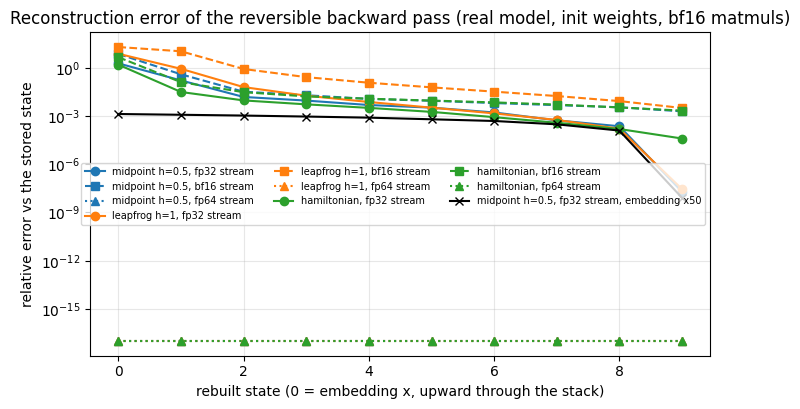

fp64 stream, bf16 autocast: largest gradient error over the 3 schemes 5.09e-03;  worst rebuilt-state error 0.00e+00
noise floor, ordinary autograd run twice, bf16 autocast : max rel. gradient difference 4.10e-03
noise floor, ordinary autograd run twice, fp32 no autocast: max rel. gradient difference 2.49e-04
midpoint h=0.5, fp64 stream, fp32 without autocast: reversible vs autograd gradient error 2.56e-04;  worst rebuilt state 0.00e+00
verdict: reversible gradient error / bf16 noise floor = 1.24


In [11]:
REAL = dict()                                     # the real 20.8M configuration
idx_real = (val_t[:2, :-1], val_t[:2, 1:])        # 2 real validation windows of 512 tokens
rows = []
# Requirement 2: is a block's output bit-identical when recomputed on the same input with autograd on?
torch.manual_seed(0)
_m = RevLM(Config()).cuda()
with torch.autocast("cuda", dtype=torch.bfloat16):
    _x = _m.emb(val_t[:2, :-1]).double()
    with torch.no_grad():
        f_fwd = _m.blocks[3].delta(_x)
    _xg = _x.detach().requires_grad_(True)
    f_bwd = _m.blocks[3].delta(_xg)
print(f"determinism: block output, no-grad forward vs recompute with autograd, max |difference| = "
      f"{(f_fwd.float() - f_bwd.detach().float()).abs().max().item():.3e}  (0 = bit-identical)")
_xp = _x * (1 + 1e-7 * torch.randn_like(_x))
with torch.no_grad(), torch.autocast("cuda", dtype=torch.bfloat16):
    f_pert = _m.blocks[3].delta(_xp.float())
print(f"sensitivity: same block on an input perturbed by 1e-7 relative (fp32-rounding size): relative change of the "
      f"output = {((f_pert.float() - f_fwd.float()).norm() / f_fwd.float().norm()).item():.3e}")
del _m

for c in [dict(scheme="midpoint", h=0.5), dict(scheme="leapfrog", h=1.0), dict(scheme="hamiltonian")]:
    for stream in ("fp32", "bf16", "fp64"):
        err, rec, _ = grad_check(Config(stream=stream, **REAL, **c), batch=idx_real)
        rows.append((Config(**c).label(), stream, err, rec))
        print(f"real model at init, L = 10, {Config(**c).label():16s} stream {stream}: max rel. gradient error vs autograd "
              f"{err:.2e};  rebuilt x rel. error {rec[0]:.2e};  worst rebuilt state {max(rec):.2e}")

fig, ax = plt.subplots(figsize=(8, 4.2))
err, rec, _ = grad_check(Config(scheme="midpoint", h=0.5, emb_mult=50.0), batch=idx_real)
print(f"real model at init, L = 10, midpoint h=0.5, stream fp32 with embedding x50 (stream rms ~1): max rel. gradient "
      f"error vs autograd {err:.2e};  rebuilt x rel. error {rec[0]:.2e};  worst rebuilt state {max(rec):.2e}")
emb50 = (err, rec)

for (lab, stream, err, rec), col in zip(rows, ["C0"] * 3 + ["C1"] * 3 + ["C2"] * 3):
    ax.semilogy(range(len(rec)), np.maximum(rec, 1e-17), {"fp32": "o-", "bf16": "s--", "fp64": "^:"}[stream], color=col,
                label=f"{lab}, {stream} stream")
ax.set_xlabel("rebuilt state (0 = embedding x, upward through the stack)")
ax.set_ylabel("relative error vs the stored state")
ax.set_title("Reconstruction error of the reversible backward pass (real model, init weights, bf16 matmuls)")
ax.semilogy(range(len(emb50[1])), np.maximum(emb50[1], 1e-17), "kx-", label="midpoint h=0.5, fp32 stream, embedding x50")
ax.legend(fontsize=7, ncol=3); ax.grid(alpha=0.3)
savefig("reconstruction_error_by_state")

fp64_errs = [err for lab, stream, err, rec in rows if stream == "fp64"]
fp64_recon = max(max(rec) for lab, stream, err, rec in rows if stream == "fp64")
floor_amp = autograd_repeat_error(Config(scheme="midpoint", h=0.5, stream="fp64"), idx_real)
floor_fp32 = autograd_repeat_error(Config(scheme="midpoint", h=0.5, stream="fp64"), idx_real, amp=False)
err_fp32, rec_fp32, _ = grad_check(Config(scheme="midpoint", h=0.5, stream="fp64"), batch=idx_real, amp=False)
print(f"fp64 stream, bf16 autocast: largest gradient error over the 3 schemes {max(fp64_errs):.2e};  "
      f"worst rebuilt-state error {fp64_recon:.2e}")
print(f"noise floor, ordinary autograd run twice, bf16 autocast : max rel. gradient difference {floor_amp:.2e}")
print(f"noise floor, ordinary autograd run twice, fp32 no autocast: max rel. gradient difference {floor_fp32:.2e}")
print(f"midpoint h=0.5, fp64 stream, fp32 without autocast: reversible vs autograd gradient error {err_fp32:.2e};  "
      f"worst rebuilt state {max(rec_fp32):.2e}")
print(f"verdict: reversible gradient error / bf16 noise floor = {max(fp64_errs) / max(floor_amp, 1e-30):.2f}")
RESULTS["precision_check"] = {"rows": [(l, st, e, max(r)) for l, st, e, r in rows], "emb50": (emb50[0], max(emb50[1])),
                              "floor_amp": floor_amp, "floor_fp32": floor_fp32, "fp32_noamp": (err_fp32, max(rec_fp32))}
assert fp64_recon < 1e-9, ("the fp64 stream does not rebuild the hidden states exactly: stop here and investigate "
                           "before spending GPU time on training")

In [12]:
print("reconstruction and gradient error vs step size h and depth L (init weights, 2 real windows)")
hl_rows = []
for stream in ("fp32", "fp64"):
    for scheme in ("midpoint", "leapfrog"):
        for h in (0.25, 0.5, 1.0):
            for L in (10, 40):
                err, rec, _ = grad_check(Config(scheme=scheme, h=h, n_layer=L, stream=stream), batch=idx_real)
                hl_rows.append((stream, scheme, h, L, err, rec[0], max(rec)))
                print(f"  stream {stream}  {scheme:8s} h = {h:4.2f}  L = {L:2d}: max rel. gradient error {err:.2e};  "
                      f"rebuilt x {rec[0]:.2e};  worst state {max(rec):.2e}")
RESULTS["recon_vs_h_L"] = hl_rows

reconstruction and gradient error vs step size h and depth L (init weights, 2 real windows)
  stream fp32  midpoint h = 0.25  L = 10: max rel. gradient error 4.47e-02;  rebuilt x 3.13e-01;  worst state 3.13e-01
  stream fp32  midpoint h = 0.25  L = 40: max rel. gradient error 2.35e-01;  rebuilt x 7.59e-01;  worst state 7.59e-01
  stream fp32  midpoint h = 0.50  L = 10: max rel. gradient error 1.78e-01;  rebuilt x 1.91e+00;  worst state 1.91e+00
  stream fp32  midpoint h = 0.50  L = 40: max rel. gradient error 9.63e-01;  rebuilt x 3.22e+00;  worst state 3.22e+00
  stream fp32  midpoint h = 1.00  L = 10: max rel. gradient error 4.14e-01;  rebuilt x 7.28e+00;  worst state 7.28e+00
  stream fp32  midpoint h = 1.00  L = 40: max rel. gradient error 1.11e+00;  rebuilt x 9.07e+00;  worst state 9.07e+00
  stream fp32  leapfrog h = 0.25  L = 10: max rel. gradient error 4.67e-02;  rebuilt x 5.85e-02;  worst state 5.85e-02
  stream fp32  leapfrog h = 0.25  L = 40: max rel. gradient error 4.37e-01;

**Observations (§4.3).** All numbers at initialisation, 2 real windows, bf16 autocast.

| stream | midpoint $h = 0.5$: grad error / rebuilt-x error | leapfrog $h = 1$ | Hamiltonian |
|---|---|---|---|
| fp32 | 17.7% / 191% | 91.5% / 758% | 53.2% / 159% |
| bf16 | 139% / 734% | 110% / 1,990% | 172% / 464% |
| **fp64** | **0.51% / 0 (bit-exact)** | **0.45% / 0** | **0.43% / 0** |
| fp32, embedding × 50 | 0.47% / 0.135% | – | – |

* **Determinism holds:** a block recomputed with autograd on gives *bit-identical* output (difference 0.000).
* **The staircase effect is real:** perturbing a block's input by 10⁻⁷ (fp32 rounding size) changes its output by
  **3.75 × 10⁻³**, i.e. ≈ 37,000× more, because the bf16 casts inside the block flip. That is why the fp32 stream fails.
* **fp64 rebuilds every state exactly (error 0.00)** for all schemes, step sizes and depths (the 24-row sweep).
* **The remaining 0.4–0.7% gradient difference is bf16 noise, not reversibility.** Ordinary autograd run twice on the
  same input already differs by **4.10 × 10⁻³** (the bf16 noise floor); the reversible error is 1.24× that. Without
  autocast (fp32) the floor is 2.49 × 10⁻⁴ and the reversible error is **2.56 × 10⁻⁴**: the same.
* **Answer to "is fp64 needed?":** no, *if the stream is well scaled*. Multiplying the embedding by 50 (stream rms ≈ 1)
  makes the fp32 stream's gradient error **4.68 × 10⁻³**, at the bf16 floor, with a 0.14% rebuild error. Our tiny
  embedding (std 0.02) was what made fp32 fail.
* With an fp32 stream the error grows with $h$ and with depth (midpoint $h = 1$, $L = 40$: rebuilt-x error 907%;
  leapfrog $h = 0.25$, $L = 10$: 5.9%). With fp64 the gradient error grows only slightly with depth (0.51% → 0.65% for
  midpoint from $L = 10$ to $40$), which is more bf16 operations, not reconstruction error.

## 5. Task 1 — Baseline: 50M tokens at a fixed batch of 64 × 512

**Setup (shared by every run).**

| | |
|---|---|
| batch | $B = 64$ sequences × $T = 512$ = **32,768 tokens per step** → $50{,}000{,}000 / 32{,}768 = $ **1,525 steps** |
| optimizer | AdamW, $\beta = (0.9, 0.95)$, weight decay 0.1 on matrices, gradient clipping at 1.0 |
| learning rate | peak $1.5 \times 10^{-3}$ (near the Assignment 11 sweep optimum for $D = 384$), 2% linear warm-up (31 steps), cosine decay to 10% |
| precision | bf16 autocast for matrix products; fp32 weights, gradients, Adam state and residual stream |
| loss | cross-entropy in chunks of 8,192 tokens, each chunk checkpointed (§8.3 shows why) |
| evaluation | 256 validation windows (131k tokens) every 100 steps; 1,024 windows (524k tokens) at the end |
| speed | tokens / s of pure training-step time (forward + backward + clip + AdamW), after 5 warm-up steps, evaluation excluded |
| peak memory | `torch.cuda.max_memory_allocated()` over the run |

**Hand predictions.**

* Fixed memory: weights 4 B + gradients 4 B + Adam's two averages 8 B = 16 bytes per weight (no bf16 copy: autocast
  casts on the fly) → $20.85\text{M} \times 16 = 334$ MB = **0.31 GiB**.
* Activations: §3.1 → about **5.1 GiB** for the 10 blocks, plus the embedding output, final norm and one 8,192-token
  logits chunk (8,192 × 8,192 × (2 + 4 + 4) bytes ≈ 0.6 GiB) → **peak ≈ 6–6.5 GiB**.
* Speed: about $6 \times 20.85\text{M} + 12 L T D \approx 149$ MFLOP per token. The L4's dense bf16 peak is about 121
  TFLOP/s; small matrices ($D = 384$), unfused norms/RoPE and no `torch.compile` should land around 20–30% of it
  (**MFU**, *model FLOPs utilisation* = achieved FLOP/s ÷ peak FLOP/s) → **≈ 160–250k tokens/s**, ≈ 4–5 min per run.
* Loss: TinyStories models of this size reach a validation loss in the 1.3–1.8 range after a few tens of millions of tokens.

In [13]:
L4_PEAK_TFLOPS = 121.0                                    # NVIDIA L4 dense bf16 tensor-core peak (spec sheet)
FLOP_PER_TOKEN = 6 * 20_848_512 + 12 * 10 * SEQ * 384     # 6N + 12 L T D (attention scores and weighted sum)

def summarize(r, ref=None):
    "One-paragraph printout of a run's result dict, optionally compared with a reference run."
    mfu = r["tok_per_s"] * FLOP_PER_TOKEN / (L4_PEAK_TFLOPS * 1e12)
    print(f"run                         : {r['label']}  (batch {r['batch']} x {r['seq']} = {r['tokens_per_step']:,} tokens/step)")
    print(f"optimizer steps             : {r['steps']:,} of {r['planned_steps']:,} planned;  peak lr {r['lr']:.2e}, warm-up {r['warmup_steps']} steps"
          + ("   ** DIVERGED **" if r["diverged"] else ""))
    print(f"final train loss (mean of last 20 steps): {r['final_train']:.4f}")
    print(f"final validation loss (524k tokens)     : {r['final_val']:.4f}")
    print(f"speed                       : {r['tok_per_s']:,.0f} tokens/s  (MFU {mfu:.1%} of {L4_PEAK_TFLOPS:.0f} TFLOP/s, "
          f"6N + 12LTD = {FLOP_PER_TOKEN / 1e6:.0f} MFLOP/token)")
    print(f"peak memory allocated       : {r['peak_gib']:.3f} GiB")
    print(f"training time / wall time   : {r['train_time_s'] / 60:.1f} min / {r['wall_s'] / 60:.1f} min")
    if ref is not None:
        print(f"vs {ref['label']:24s}: val loss {r['final_val'] - ref['final_val']:+.4f},  speed x{r['tok_per_s'] / ref['tok_per_s']:.3f},  "
              f"peak memory x{r['peak_gib'] / ref['peak_gib']:.3f}")

BASE_CFG = Config()                                        # scheme "euler" = the standard transformer, stored activations
res = train(BASE_CFG, train_tok, val_t, batch=64, total_tokens=TRAIN_TOKENS, log_every=100)
RESULTS["baseline"] = res; save_results()
print()
summarize(res)

  [euler] step     1/1525  tokens   0.03M  train loss 9.0816  grad norm 4.558  lr 5.00e-05
  [euler] step   100/1525  tokens   3.28M  train loss 3.8977  grad norm 0.842  lr 1.49e-03   val 4.0163
  [euler] step   200/1525  tokens   6.55M  train loss 3.1736  grad norm 0.434  lr 1.46e-03   val 3.2311
  [euler] step   300/1525  tokens   9.83M  train loss 2.7622  grad norm 0.502  lr 1.39e-03   val 2.8289
  [euler] step   400/1525  tokens  13.11M  train loss 2.4477  grad norm 0.391  lr 1.31e-03   val 2.5684
  [euler] step   500/1525  tokens  16.38M  train loss 2.7114  grad norm 0.320  lr 1.20e-03   val 2.3740
  [euler] step   600/1525  tokens  19.66M  train loss 2.2480  grad norm 0.412  lr 1.07e-03   val 2.2431
  [euler] step   700/1525  tokens  22.94M  train loss 2.4957  grad norm 0.270  lr 9.35e-04   val 2.1340
  [euler] step   800/1525  tokens  26.21M  train loss 1.9982  grad norm 0.316  lr 7.94e-04   val 2.0357
  [euler] step   900/1525  tokens  29.49M  train loss 1.9399  grad norm 0.409

**Observations (§5).** The baseline trained cleanly: loss 9.08 → validation **1.909** after 1,525 steps (train loss,
mean of the last 20 steps, 1.896); validation fell every evaluation. Two predictions were off:

* **Speed: 71,229 tokens/s, MFU 8.8%**, about 2.3–3.5× below my 160–250k prediction. A 20M model with $D = 384$ has
  small matrix products; the unfused RMSNorm/RoPE/SwiGLU element-wise work, the fp32 copies and the checkpointed
  cross-entropy (the head runs twice) take a large share of the step, and there is no `torch.compile`. Run time 11.7 min.
* **Reading the curves:** the evaluations during training use the first 256 validation windows; the final number
  uses all 1,024. The last point of every validation curve therefore jumps up (1.77 → 1.91 here) — the first 256
  windows are evidently easier — not because the model got worse. All reported losses use the 1,024 windows.
* **Peak memory: 8.23 GiB**, against 6–6.5 GiB predicted. §8.1 measures why: 225 KiB of activations per token, not the
  ≈ 171 I counted; my hand-written RMSNorm keeps several fp32 intermediates (input, $x^2$ mean, $x \cdot \text{rsqrt}$), and the
  dtype casts keep extra copies.

## 6. Which reversible variant? Screening at 5M tokens

Ten short runs with identical data, seed, batch (64 × 512) and learning-rate schedule (152 steps each, cosine over the
short run), all through the real reversible backward (`reversible=True`), with the **fp64 stream** from §4.3, plus two
**fp32-stream** runs as a measured counter-example (their gradients are the inexact ones of §4.3):

| run | why |
|---|---|
| baseline (Euler, stored) | reference at the same budget |
| midpoint $h = 0.25$, $0.5$, $1.0$ | $2h$ is the weight on each block's update; $h = 0.5$ matches the standard block's scale |
| midpoint $h = 0.5$, Euler start | the textbook starting state instead of the ghost state (§3.3) |
| leapfrog $h = 0.5$, $1.0$ | $h^2$ weights the "acceleration"; the stream accumulates a velocity, so large $h$ may grow too fast |
| Hamiltonian | two streams, each receiving only half of the sub-layers |
| midpoint $h = 0.5$ and leapfrog $h = 0.5$, **fp32 stream** | the same models trained on inexact gradients: how much do the errors of §4.3 cost? |

Hand predictions:
* **midpoint $h = 0.5$** should be close to the baseline: at this $h$ it adds each block's full update, just to the
  state two steps back.
* **leapfrog** behaves differently: updates accumulate in the velocity $v^\ell = p^\ell - p^{\ell-1}$, so the stream
  grows faster with depth; $h = 1$ might be unstable early, $h = 0.5$ is gentler.
* **Hamiltonian**: each stream sees only one kind of sub-layer, and both start as the same embedding; I expect it to
  learn a little slower.
* Reversible speeds: 15–20% below the baseline (§3.4). Peak memory: about 1–1.5 GiB instead of ~6 GiB.

The winner (lowest validation loss among the exact, fp64-stream reversible runs that did not diverge) goes to the
50M-token run in §7.

(The first run of this notebook screened the same variants with the fp32 stream; its validation losses at 5M tokens
were baseline 4.232, midpoint $h = 0.25 / 0.5 / 1$: 4.831 / 4.730 / 4.857, midpoint Euler start 4.868, leapfrog
$h = 0.5 / 1$: 3.960 / 4.509, Hamiltonian 4.281. Those numbers were produced with the inexact gradients.)

In [14]:
SCREEN_TOKENS = 5_000_000
X = dict(reversible=True, stream="fp64")              # exact reversible runs
SCREEN = [Config(),
          Config(scheme="midpoint", h=0.25, **X),
          Config(scheme="midpoint", h=0.5, **X),
          Config(scheme="midpoint", h=1.0, **X),
          Config(scheme="midpoint", h=0.5, start="euler", **X),
          Config(scheme="leapfrog", h=0.5, **X),
          Config(scheme="leapfrog", h=1.0, **X),
          Config(scheme="hamiltonian", **X),
          Config(scheme="midpoint", h=0.5, reversible=True),           # fp32 stream: inexact gradients
          Config(scheme="leapfrog", h=0.5, reversible=True)]
screen = []
for c in SCREEN:
    r = train(c, train_tok, val_t, batch=64, total_tokens=SCREEN_TOKENS, eval_every=25, eval_windows=128,
              final_eval_windows=512, quiet=True)
    screen.append(r)
    print(f"screening {r['label']:28s}: val loss {r['final_val']:.4f}  train loss {r['final_train']:.4f}  "
          f"speed {r['tok_per_s']:>9,.0f} tok/s  peak {r['peak_gib']:.3f} GiB" + ("  DIVERGED" if r["diverged"] else ""))
RESULTS["screen"] = screen; save_results()

screening euler                       : val loss 4.2158  train loss 4.2408  speed    71,233 tok/s  peak 8.230 GiB
screening midpoint h=0.25 rev fp64    : val loss 4.7543  train loss 4.7585  speed    47,819 tok/s  peak 2.400 GiB
screening midpoint h=0.5 rev fp64     : val loss 4.5758  train loss 4.6049  speed    47,822 tok/s  peak 2.400 GiB
screening midpoint h=1 rev fp64       : val loss 4.5212  train loss 4.5410  speed    47,816 tok/s  peak 2.400 GiB
screening midpoint h=0.5 start=euler rev fp64: val loss 4.6939  train loss 4.7115  speed    48,197 tok/s  peak 2.391 GiB
screening leapfrog h=0.5 rev fp64     : val loss 3.8746  train loss 3.8869  speed    45,168 tok/s  peak 2.438 GiB
screening leapfrog h=1 rev fp64       : val loss 3.9194  train loss 3.9294  speed    45,163 tok/s  peak 2.438 GiB
screening hamiltonian rev fp64        : val loss 4.0332  train loss 4.0480  speed    48,305 tok/s  peak 2.047 GiB
screening midpoint h=0.5 rev          : val loss 4.8096  train loss 4.8110  speed

variant                        val loss @5M  vs baseline      tok/s  speed ratio  peak GiB
euler                                4.2158      +0.0000     71,233        1.000     8.230
midpoint h=0.25 rev fp64             4.7543      +0.5385     47,819        0.671     2.400
midpoint h=0.5 rev fp64              4.5758      +0.3600     47,822        0.671     2.400
midpoint h=1 rev fp64                4.5212      +0.3055     47,816        0.671     2.400
midpoint h=0.5 start=euler rev fp64       4.6939      +0.4781     48,197        0.677     2.391
leapfrog h=0.5 rev fp64              3.8746      -0.3412     45,168        0.634     2.438
leapfrog h=1 rev fp64                3.9194      -0.2964     45,163        0.634     2.438
hamiltonian rev fp64                 4.0332      -0.1826     48,305        0.678     2.047
midpoint h=0.5 rev                   4.8096      +0.5939     53,820        0.756     1.885
leapfrog h=0.5 rev                   3.9443      -0.2715     52,096        0.731     

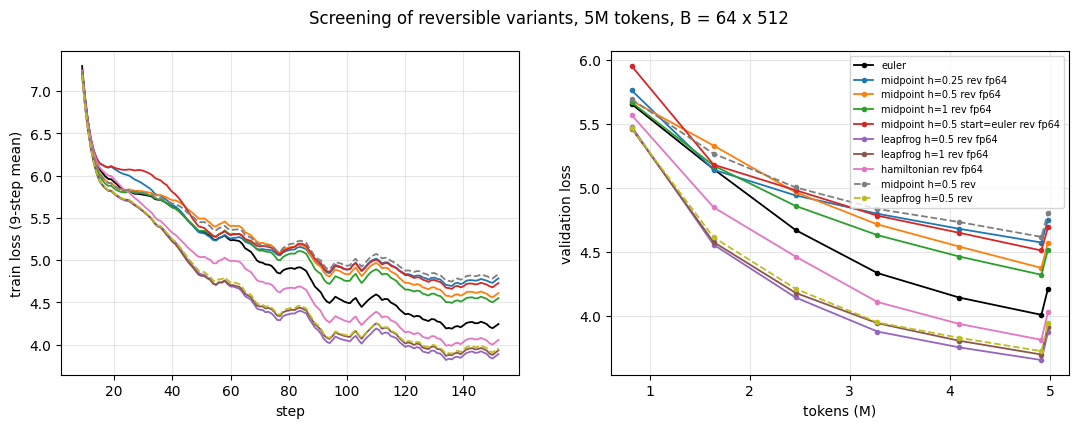

In [15]:
base_s = screen[0]
print(f"{'variant':30s} {'val loss @5M':>12s} {'vs baseline':>12s} {'tok/s':>10s} {'speed ratio':>12s} {'peak GiB':>9s}")
for r in screen:
    print(f"{r['label']:30s} {r['final_val']:12.4f} {r['final_val'] - base_s['final_val']:+12.4f} {r['tok_per_s']:10,.0f} "
          f"{r['tok_per_s'] / base_s['tok_per_s']:12.3f} {r['peak_gib']:9.3f}")
cands = [r for r in screen[1:] if r["stream"] == "fp64" and not r["diverged"] and math.isfinite(r["final_val"])]
best_s = min(cands, key=lambda r: r["final_val"])
BEST_CFG = SCREEN[screen.index(best_s)]
print(f"\nwinner (lowest validation loss among exact reversible variants): {best_s['label']}  ->  {BEST_CFG}")
for a_, b_ in [("midpoint h=0.5 rev fp64", "midpoint h=0.5 rev"), ("leapfrog h=0.5 rev fp64", "leapfrog h=0.5 rev")]:
    ra, rb = [r for r in screen if r["label"] == a_][0], [r for r in screen if r["label"] == b_][0]
    print(f"cost of the inexact fp32-stream gradients, {b_}: val loss {rb['final_val']:.4f} vs exact {ra['final_val']:.4f} "
          f"({rb['final_val'] - ra['final_val']:+.4f})")

fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
for r in screen:
    st = ("--" if r["stream"] == "fp32" else "-") if r["reversible"] else "k-"
    tr = np.array([hh[2] for hh in r["hist"]])
    sm = np.convolve(tr, np.ones(9) / 9, mode="valid")
    axs[0].plot(np.arange(len(sm)) + 9, sm, st, lw=1.3, label=r["label"])
    vh = np.array(r["val_hist"])
    axs[1].plot(vh[:, 1] / 1e6, vh[:, 2], st + "o", ms=3, lw=1.3, label=r["label"])
axs[0].set_ylim(top=min(8, axs[0].get_ylim()[1])); axs[0].set_xlabel("step"); axs[0].set_ylabel("train loss (9-step mean)")
axs[1].set_xlabel("tokens (M)"); axs[1].set_ylabel("validation loss"); axs[1].set_ylim(top=min(7, axs[1].get_ylim()[1]))
for a in axs: a.grid(alpha=0.3)
axs[1].legend(fontsize=7)
fig.suptitle("Screening of reversible variants, 5M tokens, B = 64 x 512")
savefig("variant_screening")

**Observations (§6).** At 5M tokens (baseline 4.216):

| variant (fp64 stream unless noted) | val loss | vs baseline | speed vs baseline | peak GiB |
|---|--:|--:|--:|--:|
| **leapfrog $h = 0.5$** | **3.875** | **−0.341** | 0.63 | 2.44 |
| leapfrog $h = 1$ | 3.919 | −0.296 | 0.63 | 2.44 |
| Hamiltonian | 4.033 | −0.183 | 0.68 | 2.05 |
| midpoint $h = 1$ | 4.521 | +0.306 | 0.67 | 2.40 |
| midpoint $h = 0.5$ | 4.576 | +0.360 | 0.67 | 2.40 |
| midpoint $h = 0.5$, Euler start | 4.694 | +0.478 | 0.68 | 2.39 |
| midpoint $h = 0.25$ | 4.754 | +0.539 | 0.67 | 2.40 |
| midpoint $h = 0.5$, **fp32 stream** | 4.810 | +0.594 | 0.76 | 1.89 |
| leapfrog $h = 0.5$, **fp32 stream** | 3.944 | −0.272 | 0.73 | 1.89 |

* **Leapfrog $h = 0.5$ is the variant that worked best**, and it was 0.34 *ahead* of the baseline at 5M tokens. My
  prediction ("midpoint ≈ baseline, leapfrog risky") was backwards.
* **Why midpoint lags (interpretation):** unrolling $p^{\ell+1} = p^{\ell-1} + 2h f_\ell(p^\ell)$ from the ghost start gives
  $p^{10} = x + 2h\,[f_1(p^1) + f_3(p^3) + \dots + f_9(p^9)]$: only the odd blocks write directly to the output, and the
  even blocks reach it only through the inputs they feed. It behaves like two interleaved half-depth stacks. Leapfrog
  accumulates every update in a velocity, $p^{10} = x + h^2 \sum_k (10 - k)\, f_k(p^k)$, so every block reaches the
  output, the early ones with the most weight (a momentum-like stream). The stream rms in the trained model grows from 0.05 to 11.1 (§7), consistent with this.
* **The Euler start hurt midpoint** (+0.12 vs the ghost start); larger $h$ helped midpoint (0.25 → 1: 4.75 → 4.52).
* **Inexact fp32-stream gradients cost loss:** +0.234 for midpoint and +0.070 for leapfrog against their exact
  versions, at the same data and seed. Bad gradients are measurably worse, not just "noisy".
* **Speed:** the exact reversible runs reach 0.63–0.68 of the baseline, below my 0.80–0.85 prediction. The fp64
  stream is part of it: the fp32-stream reversible runs reach 0.73–0.76, and the *stored* fp64 wiring in §8.1 already
  runs at 0.82 of the baseline at $B = 64$ (the L4's fp64 units are slow; the casts add memory traffic). The
  recompute itself costs 0.77× (reversible 45.1k vs stored-fp64 58.6k tokens/s at $B = 64$), i.e. ≈ 30% more time.
* Memory at $B = 64$: 2.0–2.4 GiB for every reversible variant against 8.23 GiB.

## 7. Task 2 — The best reversible variant, 50M tokens, same batch

Same data, seed, batch, learning rate and schedule as §5; only the wiring and the backward pass differ.

Predictions: final loss within a few hundredths of the baseline (the screening tells us the sign); speed about 15–20%
lower; peak memory ~1–1.5 GiB instead of ~6 GiB, i.e. **4–5× less** at this batch. The ratio is not larger because a
fixed part of the peak (0.31 GiB of weights and Adam state, the 0.6 GiB logits chunk) does not shrink.

After training, the gradient check is repeated **with the trained weights on real text**: training can make the blocks'
Jacobians larger than at initialisation, which would amplify reconstruction error.

In [16]:
res_rev = train(BEST_CFG, train_tok, val_t, batch=64, total_tokens=TRAIN_TOKENS, log_every=100, keep_model=True)
rev_model = res_rev.pop("model")
RESULTS["reversible"] = res_rev; save_results()
print()
summarize(res_rev, RESULTS["baseline"])

  [leapfrog h=0.5 rev fp64] step     1/1525  tokens   0.03M  train loss 9.0626  grad norm 4.783  lr 5.00e-05
  [leapfrog h=0.5 rev fp64] step   100/1525  tokens   3.28M  train loss 3.6749  grad norm 0.835  lr 1.49e-03   val 3.8075
  [leapfrog h=0.5 rev fp64] step   200/1525  tokens   6.55M  train loss 3.0660  grad norm 0.461  lr 1.46e-03   val 3.1344
  [leapfrog h=0.5 rev fp64] step   300/1525  tokens   9.83M  train loss 2.6642  grad norm 0.549  lr 1.39e-03   val 2.7286
  [leapfrog h=0.5 rev fp64] step   400/1525  tokens  13.11M  train loss 2.3742  grad norm 0.484  lr 1.31e-03   val 2.4852
  [leapfrog h=0.5 rev fp64] step   500/1525  tokens  16.38M  train loss 2.6478  grad norm 0.332  lr 1.20e-03   val 2.3197
  [leapfrog h=0.5 rev fp64] step   600/1525  tokens  19.66M  train loss 2.1926  grad norm 0.434  lr 1.07e-03   val 2.2041
  [leapfrog h=0.5 rev fp64] step   700/1525  tokens  22.94M  train loss 2.4692  grad norm 0.319  lr 9.35e-04   val 2.1045
  [leapfrog h=0.5 rev fp64] step   80

In [17]:
# Reconstruction and gradient check with the TRAINED weights, real validation text, bf16 autocast, fp32 stream.
w_trained = {k: v.detach().clone() for k, v in rev_model.state_dict().items()}
err_tr, rec_tr, per_param = grad_check(replace(BEST_CFG, reversible=False), weights=w_trained,
                                       batch=(val_t[:4, :-1], val_t[:4, 1:]))
print(f"trained {BEST_CFG.label()}: max rel. gradient error (reversible vs stored autograd) = {err_tr:.3e}")
print(f"trained {BEST_CFG.label()}: rebuilt x rel. error = {rec_tr[0]:.3e};  worst rebuilt state = {max(rec_tr):.3e}")
worst = sorted(per_param.items(), key=lambda kv: -kv[1])[:3]
print("largest per-tensor gradient differences:", ", ".join(f"{k} {v:.2e}" for k, v in worst))
with torch.no_grad():
    x = rev_model.emb(val_t[:4, :-1]).float()
    keep = []
    run_stack(rev_model, x, keep)
    st = [s if torch.is_tensor(s) else s[0] for s in keep]
    print("rms of the residual stream through the trained stack:",
          " ".join(f"{s.pow(2).mean().sqrt().item():.3f}" for s in st))
RESULTS["trained_check"] = {"grad_err": err_tr, "recon": rec_tr}
del rev_model, w_trained; gc.collect(); torch.cuda.empty_cache()

trained leapfrog h=0.5 rev fp64: max rel. gradient error (reversible vs stored autograd) = 4.298e-03
trained leapfrog h=0.5 rev fp64: rebuilt x rel. error = 0.000e+00;  worst rebuilt state = 0.000e+00
largest per-tensor gradient differences: blocks.1.attn.qkv.weight 4.30e-03, blocks.0.attn.qkv.weight 4.13e-03, blocks.2.norm1.weight 4.10e-03
rms of the residual stream through the trained stack: 0.050 0.050 0.418 0.893 1.448 2.107 2.918 3.911 5.113 6.602 8.557 11.086


**Observations (§7).** Leapfrog $h = 0.5$ with the fp64 stream, 50M tokens, same data, seed and schedule as §5:

| | baseline | reversible leapfrog | ratio |
|---|--:|--:|--:|
| final validation loss | 1.9090 | **1.8994** | −0.0096 |
| final train loss (last 20 steps) | 1.8956 | 1.8863 | −0.0093 |
| speed | 71,229 tok/s | 45,150 tok/s | **× 0.634** |
| peak memory | 8.230 GiB | **2.438 GiB** | **× 0.296** |
| training time | 11.7 min | 18.4 min | × 1.57 |

* The reversible model **matched the baseline**: it led by 0.21 at 3.3M tokens (3.81 vs 4.02), and the gap shrank
  to 0.01 by 50M. With one seed, a 0.01 difference is "no worse", not "better" (the baseline itself differed by 0.0013
  between two runs with the same seed, from non-deterministic kernels; seed-to-seed spread was not measured).
* **Trained weights, real text:** every rebuilt state is still **bit-exact (error 0)**, and the gradient error is
  4.3 × 10⁻³, at the bf16 noise floor. Training did not break reversibility.
* The residual stream's rms through the trained stack grows steadily, 0.05 → 0.42 → … → 11.09 at $p^{10}$: leapfrog's
  accumulating velocity.

## 8. Memory anatomy: where the bytes go

### 8.1 Peak memory vs batch → activation bytes per token

Peak memory is (to a good approximation) a fixed part plus a part proportional to the number of tokens:

$$ \text{peak}(B) \approx M_0 + m \cdot B T. $$

Fitting a line through probes at $B = 8 \dots 128$ gives $m$, the activation memory per token, and $M_0$. Three
models separate the two effects: the **baseline**, the **winning wiring with stored activations** (does the
architecture change itself matter?) and the **winning wiring reversible**.

Predictions: baseline $m \approx 166$ KB/token (§3.1) plus the embedding/norm/CE terms (≈ 5 KB) → about 170 KB;
same wiring stored → slightly more (its fp64 stream adds 8-byte copies); reversible with the fp64 stream → the top pair
(2 × 8D = 6 KB) + its gradients and the rebuilt pair during backward (≈ 4 × 8D = 12 KB) + one block's graph (16.6 KB) +
the embedding/norm terms (≈ 5 KB) ≈ **40 KB/token**, a **≈ 4×** reduction.

  baseline (Euler, stored)         batch    8: peak 1.827 GiB, speed 90,468 tok/s
  baseline (Euler, stored)         batch   16: peak 3.063 GiB, speed 97,846 tok/s
  baseline (Euler, stored)         batch   32: peak 4.810 GiB, speed 85,511 tok/s
  baseline (Euler, stored)         batch   64: peak 8.268 GiB, speed 71,440 tok/s
  baseline (Euler, stored)         batch  128: peak 15.185 GiB, speed 66,212 tok/s
baseline (Euler, stored)          : activation memory  224.94 KiB per token,  fixed part 1.183 GiB
  leapfrog h=0.5 fp64 (stored)     batch    8: peak 1.827 GiB, speed 81,745 tok/s
  leapfrog h=0.5 fp64 (stored)     batch   16: peak 3.063 GiB, speed 79,970 tok/s
  leapfrog h=0.5 fp64 (stored)     batch   32: peak 4.810 GiB, speed 67,570 tok/s
  leapfrog h=0.5 fp64 (stored)     batch   64: peak 8.268 GiB, speed 58,629 tok/s
  leapfrog h=0.5 fp64 (stored)     batch  128: peak 15.448 GiB, speed 55,046 tok/s
leapfrog h=0.5 fp64 (stored)      : activation memory  229.39 KiB per token,  f

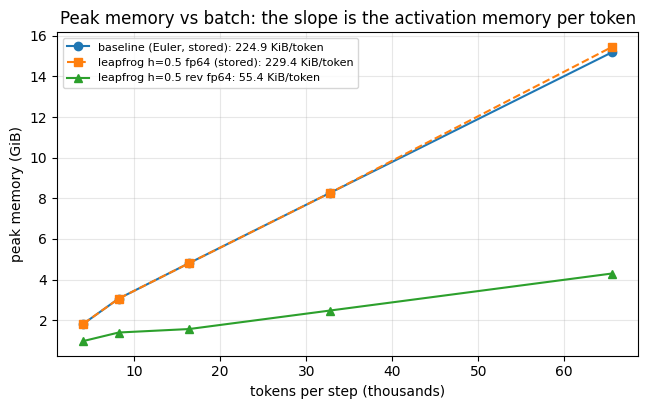

In [18]:
BATCHES = [8, 16, 32, 64, 128]
MEM_CFGS = [("baseline (Euler, stored)", BASE_CFG),
            (f"{replace(BEST_CFG, reversible=False).label()} (stored)", replace(BEST_CFG, reversible=False)),
            (f"{BEST_CFG.label()}", BEST_CFG)]
mem = {}
for name, c in MEM_CFGS:
    pk = []
    for b in BATCHES:
        r = probe(c, b, timed_steps=3)
        pk.append(r["peak_gib"])
        print(f"  {name:32s} batch {b:4d}: peak {r['peak_gib']:.3f} GiB, speed {r['tok_per_s']:,.0f} tok/s")
    tokens = np.array(BATCHES) * SEQ
    slope, icpt = np.polyfit(tokens, np.array(pk) * 2**30, 1)
    mem[name] = dict(peaks=pk, slope_kib=slope / 1024, intercept_gib=icpt / 2**30)
    print(f"{name:34s}: activation memory {slope / 1024:7.2f} KiB per token,  fixed part {icpt / 2**30:.3f} GiB")
names = list(mem)
print(f"\nactivation memory per token, baseline / reversible = {mem[names[0]]['slope_kib'] / mem[names[2]]['slope_kib']:.2f}x;  "
      f"stored wiring / baseline = {mem[names[1]]['slope_kib'] / mem[names[0]]['slope_kib']:.3f}")
RESULTS["mem_vs_batch"] = {"batches": BATCHES, **mem}; save_results()

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for (name, d), mk in zip(mem.items(), ["o-", "s--", "^-"]):
    ax.plot(np.array(BATCHES) * SEQ / 1e3, d["peaks"], mk, label=f"{name}: {d['slope_kib']:.1f} KiB/token")
ax.set_xlabel("tokens per step (thousands)"); ax.set_ylabel("peak memory (GiB)")
ax.set_title("Peak memory vs batch: the slope is the activation memory per token")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
savefig("memory_vs_batch")

### 8.2 Peak memory vs depth

The lesson's central claim (§17): with reversibility "the 96 in the calculation disappears". Here $L$ = 10, 20, 40 at
$B = 32$ (16,384 tokens). Prediction:

* baseline: $+16.6\ \text{KB} \times 16{,}384 \approx +0.26$ GiB of activations per block, plus $1.77\text{M} \times 16$ B
  = 28 MB of weights and Adam state per block → about **+0.29 GiB per layer**;
* reversible: only the 28 MB of state per layer → **+0.03 GiB per layer**, about 10× flatter.

  L = 10  baseline (Euler, stored)  : peak 4.810 GiB,  speed 85,356 tok/s,  parameters 20.8M
  L = 10  leapfrog h=0.5 rev fp64   : peak 1.565 GiB,  speed 53,335 tok/s,  parameters 20.8M
  L = 20  baseline (Euler, stored)  : peak 8.407 GiB,  speed 46,688 tok/s,  parameters 38.6M
  L = 20  leapfrog h=0.5 rev fp64   : peak 1.863 GiB,  speed 28,698 tok/s,  parameters 38.6M
  L = 40  baseline (Euler, stored)  : peak 15.601 GiB,  speed 24,871 tok/s,  parameters 74.0M
  L = 40  leapfrog h=0.5 rev fp64   : peak 2.459 GiB,  speed 14,808 tok/s,  parameters 74.0M
baseline (Euler, stored)    : peak memory grows by 368 MiB per added layer
leapfrog h=0.5 rev fp64     : peak memory grows by 31 MiB per added layer


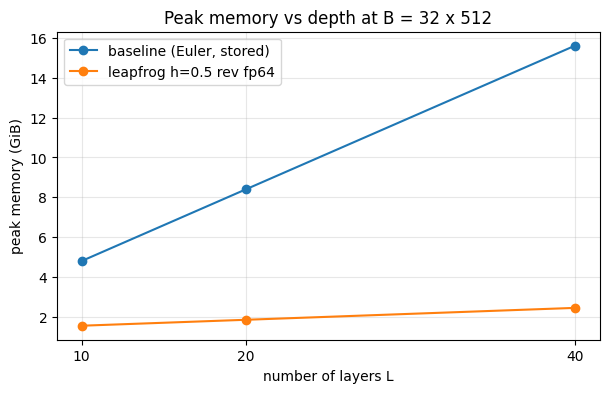

In [19]:
DEPTHS = [10, 20, 40]
depth = {"baseline (Euler, stored)": [], BEST_CFG.label(): []}
for L in DEPTHS:
    for name, c in [("baseline (Euler, stored)", replace(BASE_CFG, n_layer=L)), (BEST_CFG.label(), replace(BEST_CFG, n_layer=L))]:
        r = probe(c, 32, timed_steps=2)
        depth[name].append((r["peak_gib"], r["tok_per_s"]))
        print(f"  L = {L:2d}  {name:26s}: peak {r['peak_gib']:.3f} GiB,  speed {r['tok_per_s']:,.0f} tok/s,  "
              f"parameters {count_params(RevLM(c))['total'] / 1e6:.1f}M")
for name, v in depth.items():
    per_layer = (v[-1][0] - v[0][0]) / (DEPTHS[-1] - DEPTHS[0])
    print(f"{name:28s}: peak memory grows by {per_layer * 1024:.0f} MiB per added layer")
RESULTS["mem_vs_depth"] = {"depths": DEPTHS, **depth}; save_results()

fig, ax = plt.subplots(figsize=(7, 4))
for name, v in depth.items():
    ax.plot(DEPTHS, [a for a, _ in v], "o-", label=name)
ax.set_xlabel("number of layers L"); ax.set_ylabel("peak memory (GiB)"); ax.set_xticks(DEPTHS)
ax.set_title("Peak memory vs depth at B = 32 x 512"); ax.legend(); ax.grid(alpha=0.3)
savefig("memory_vs_depth")

### 8.3 Counter-example: the logits trap

The head produces 8,192 scores per token. Un-chunked, autograd keeps the bf16 logits (16 KB/token), the fp32 copy fed
to the softmax (32 KB) and, during backward, the fp32 gradient of the logits (32 KB): **≈ 80 KB per token**, which
is several times the ≈ 30 KB the reversible stack needs. Without chunking, the head and not the blocks would decide the
maximum batch, and reversibility would look far less useful than it is. Prediction at $B = 64$: un-chunked adds about
32,768 × 80 KB ≈ 2.5 GiB to *both* models.

In [20]:
for name, c in [("baseline", BASE_CFG), (BEST_CFG.label(), BEST_CFG)]:
    for chunk in (8192, 0):
        r = probe(replace(c, ce_chunk=chunk), 64)
        print(f"{name:22s} B = 64, cross-entropy {'chunked (8,192 tokens), checkpointed' if chunk else 'un-chunked':38s}: peak {r['peak_gib']:.3f} GiB")

baseline               B = 64, cross-entropy chunked (8,192 tokens), checkpointed  : peak 8.268 GiB
baseline               B = 64, cross-entropy un-chunked                            : peak 10.436 GiB
leapfrog h=0.5 rev fp64 B = 64, cross-entropy chunked (8,192 tokens), checkpointed  : peak 2.476 GiB
leapfrog h=0.5 rev fp64 B = 64, cross-entropy un-chunked                            : peak 3.862 GiB


**Observations (§8).**

* **Activation memory per token** (slope of peak vs tokens): baseline **224.9 KiB**, same leapfrog wiring stored
  229.4 KiB (the wiring itself changes nothing), reversible **55.4 KiB**: **4.06× less**. Fixed parts 1.18 / 1.13 /
  0.80 GiB. Both are above my hand counts (171 and 40 KiB): the baseline for the RMSNorm intermediates noted in §5,
  the reversible model for fp64 temporaries in the backward pass (rebuilt state, gradients) plus one block's full graph.
* **Depth:** at $B = 32$, peak memory grows by **368 MiB per added layer** for the baseline (4.81 → 8.41 → 15.60 GiB at
  $L$ = 10/20/40) and by **31 MiB per layer** for the reversible model (1.57 → 1.86 → 2.46 GiB), 12× flatter. 31 MiB is
  the 28 MiB of weights + Adam state a layer adds: the reversible activations do not grow with depth at all. At 40
  layers (74M parameters) the reversible model needs 6.3× less memory.
* **The logits trap:** without chunking, the cross-entropy adds 2.17 GiB to the baseline at $B = 64$ (8.27 → 10.44) and
  1.39 GiB to the reversible model (2.48 → 3.86): +56% of the reversible peak. Unchunked, the head, not the blocks,
  would dominate the reversible model's memory.

## 9. Task 3 — The largest batch, and 50M tokens at the reversible maximum

### 9.1 How far does reversibility push the batch?

`max_batch` doubles the batch from 32 sequences until two training steps run out of memory, then bisects to a multiple
of 32 sequences. The same procedure is used for the baseline and the reversible model.

Prediction from §8.1 (to be compared with its measured slopes): usable memory ≈ 22 GiB minus the fixed part (≈ 1 GiB)
leaves ≈ 21 GiB for activations → baseline $21\ \text{GiB} / 170\ \text{KB} \approx 130$k tokens ≈ **250 sequences**;
reversible $21\ \text{GiB} / 40\ \text{KB} \approx 550$k tokens ≈ **1,100 sequences** → about **4× larger**.

In [21]:
mb_base, pk_base, log_base = max_batch(BASE_CFG)
mb_rev, pk_rev, log_rev = max_batch(BEST_CFG)
print(f"\nlargest batch that fits, baseline   : {mb_base:5d} x {SEQ} = {mb_base * SEQ:>9,} tokens (peak {pk_base:.2f} GiB of {GPU_GIB:.2f})")
print(f"largest batch that fits, reversible : {mb_rev:5d} x {SEQ} = {mb_rev * SEQ:>9,} tokens (peak {pk_rev:.2f} GiB of {GPU_GIB:.2f})")
print(f"reversibility raises the maximum batch by x{mb_rev / mb_base:.2f}")
RESULTS["max_batch"] = {"baseline": mb_base, "baseline_peak": pk_base, "reversible": mb_rev, "reversible_peak": pk_rev,
                        "log_base": log_base, "log_rev": log_rev}; save_results()

  [euler] batch    32 x 512 =    16,384 tokens: fits, peak 4.81 GiB
  [euler] batch    64 x 512 =    32,768 tokens: fits, peak 8.27 GiB
  [euler] batch   128 x 512 =    65,536 tokens: fits, peak 15.18 GiB
  [euler] batch   256 x 512 =   131,072 tokens: out of memory
  [euler] batch   192 x 512 =    98,304 tokens: out of memory
  [euler] batch   160 x 512 =    81,920 tokens: fits, peak 18.64 GiB
  [leapfrog h=0.5 rev fp64] batch    32 x 512 =    16,384 tokens: fits, peak 1.57 GiB
  [leapfrog h=0.5 rev fp64] batch    64 x 512 =    32,768 tokens: fits, peak 2.48 GiB
  [leapfrog h=0.5 rev fp64] batch   128 x 512 =    65,536 tokens: fits, peak 4.30 GiB
  [leapfrog h=0.5 rev fp64] batch   256 x 512 =   131,072 tokens: fits, peak 7.94 GiB
  [leapfrog h=0.5 rev fp64] batch   512 x 512 =   262,144 tokens: fits, peak 15.23 GiB
  [leapfrog h=0.5 rev fp64] batch  1024 x 512 =   524,288 tokens: out of memory
  [leapfrog h=0.5 rev fp64] batch   768 x 512 =   393,216 tokens: out of memory
  [leapfrog

### 9.2 Throughput vs batch

Bigger batches only raise tokens/s while the GPU is not yet saturated. At 32,768 tokens per step the matrix products
are already large ($32{,}768 \times 384$ by $384 \times 1152$), so I expect little gain past $B = 64$, and possibly a
slow decline as the attention and memory traffic per step grow. Three timed steps per point, after two warm-up steps.

  baseline               batch    32:    85,376 tok/s, peak 4.81 GiB
  baseline               batch    64:    71,430 tok/s, peak 8.27 GiB
  baseline               batch   128:    66,195 tok/s, peak 15.18 GiB
  baseline               batch   160:    65,734 tok/s, peak 18.64 GiB
  leapfrog h=0.5 rev fp64 batch    32:    53,495 tok/s, peak 1.57 GiB
  leapfrog h=0.5 rev fp64 batch    64:    45,125 tok/s, peak 2.48 GiB
  leapfrog h=0.5 rev fp64 batch   128:    42,460 tok/s, peak 4.30 GiB
  leapfrog h=0.5 rev fp64 batch   256:    42,041 tok/s, peak 7.94 GiB
  leapfrog h=0.5 rev fp64 batch   512:    41,454 tok/s, peak 15.23 GiB
  leapfrog h=0.5 rev fp64 batch   704:    38,205 tok/s, peak 20.69 GiB


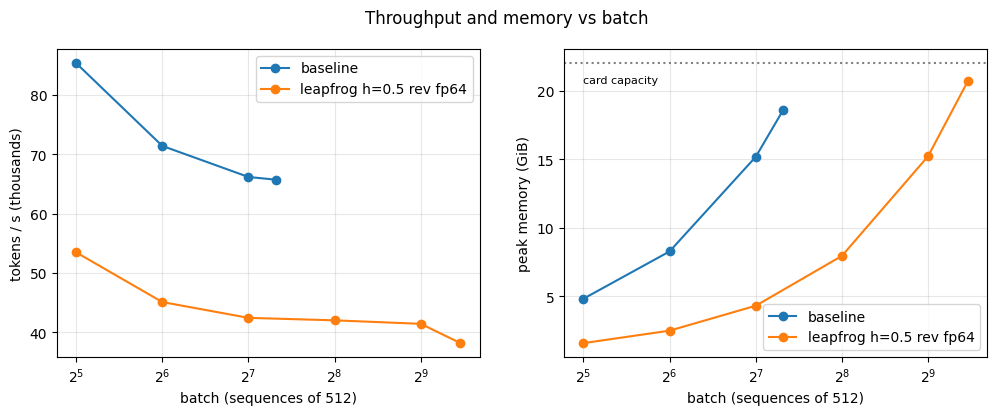

In [22]:
TP_BASE = sorted({32, 64, 128, mb_base})
TP_REV = sorted({32, 64, 128, 256, 512, 1024, mb_rev} - {b for b in [512, 1024] if b > mb_rev})
tput = {"baseline": [], BEST_CFG.label(): []}
for name, c, bs in [("baseline", BASE_CFG, TP_BASE), (BEST_CFG.label(), BEST_CFG, TP_REV)]:
    for b in bs:
        r = probe(c, b, timed_steps=3)
        tput[name].append((b, r["tok_per_s"], r["peak_gib"]))
        print(f"  {name:22s} batch {b:5d}: {r['tok_per_s']:>9,.0f} tok/s, peak {r['peak_gib']:.2f} GiB" if r["ok"] else f"  {name} batch {b}: OOM")
RESULTS["throughput_vs_batch"] = tput; save_results()

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for name, v in tput.items():
    v = [t for t in v if t[1] is not None]
    axs[0].plot([t[0] for t in v], [t[1] / 1e3 for t in v], "o-", label=name)
    axs[1].plot([t[0] for t in v], [t[2] for t in v], "o-", label=name)
for a in axs:
    a.set_xscale("log", base=2); a.set_xlabel("batch (sequences of 512)"); a.grid(alpha=0.3); a.legend()
axs[0].set_ylabel("tokens / s (thousands)"); axs[1].set_ylabel("peak memory (GiB)")
axs[1].axhline(GPU_GIB, color="gray", ls=":"); axs[1].text(32, GPU_GIB * 0.96, "card capacity", fontsize=8, va="top")
fig.suptitle("Throughput and memory vs batch")
savefig("throughput_vs_batch")

### 9.3 50M tokens at the reversible maximum: why the loss is expected to be worse

The token budget is fixed, so the number of optimizer steps is

$$ \text{steps} = \frac{50{,}000{,}000}{B \times 512}. $$

| run | batch | tokens / step | optimizer steps |
|---|--:|--:|--:|
| §5, §7 | 64 | 32,768 | 1,525 |
| §9 (if $B_{\max} \approx 1{,}100$) | ≈ 1,100 | ≈ 563k | **≈ 89** |

Each step is one weight update. A bigger batch makes the gradient less noisy (noise shrinks like $1/\sqrt{B}$), but once
the gradient is already clean (the batch is beyond the *critical batch size*), averaging 17× more tokens gives nearly
the same direction, and the model simply takes 17× fewer steps. So with the learning rate unchanged, the run would end
roughly where the baseline was after ~90 steps, early in training.

Two adjustments, standard practice for a larger batch:
* **learning rate** scaled by $\sqrt{B / 64}$ (the usual rule for Adam), **capped at $4 \times 10^{-3}$** so the first
  steps do not diverge: $1.5 \times 10^{-3} \sqrt{17} \approx 6 \times 10^{-3}$ would be too high for this model;
* **warm-up 10%** of the steps (≈ 9 steps); 2% would be a single step at full learning rate from random weights.

Batch used: the maximum from §9.1 minus ≈ 5% headroom (rounded down to a multiple of 32), because a real 50M-token run
also holds evaluation buffers and suffers allocator fragmentation that a 2-step probe does not.

Prediction: peak memory near the card's capacity, speed close to the B = 64 reversible run (§9.2), and a final loss
**clearly worse** than §7, perhaps 0.5–1.0 higher. That would not be a failure of reversibility: it is the fixed-token
budget turning a bigger batch into fewer updates. The memory headroom is the result; how to spend it is a separate
choice (§10 discusses better uses).

In [7]:
B_RUN = max(32, int(mb_rev * 0.95) // 32 * 32)
LR_RUN = min(1.5e-3 * math.sqrt(B_RUN / 64), 4e-3)
steps_run = TRAIN_TOKENS // (B_RUN * SEQ)
print(f"max-batch run: batch {B_RUN} x {SEQ} = {B_RUN * SEQ:,} tokens/step -> {steps_run} optimizer steps;  "
      f"peak lr {LR_RUN:.2e} (sqrt rule would give {1.5e-3 * math.sqrt(B_RUN / 64):.2e});  warm-up 10% = {max(1, round(0.1 * steps_run))} steps")
while True:
    try:
        res_max = train(BEST_CFG, train_tok, val_t, batch=B_RUN, total_tokens=TRAIN_TOKENS, lr=LR_RUN, warmup_frac=0.10,
                        eval_every=max(1, steps_run // 10), eval_windows=256, log_every=max(1, steps_run // 20))
        break
    except torch.cuda.OutOfMemoryError:
        gc.collect(); torch.cuda.empty_cache()
        B_RUN = int(B_RUN * 0.9) // 32 * 32
        steps_run = TRAIN_TOKENS // (B_RUN * SEQ)
        print(f"out of memory during the run: retrying with batch {B_RUN}")
RESULTS["reversible_max_batch"] = res_max; save_results()
print()
summarize(res_max, RESULTS["reversible"])

max-batch run: batch 640 x 512 = 327,680 tokens/step -> 152 optimizer steps;  peak lr 4.00e-03 (sqrt rule would give 4.74e-03);  warm-up 10% = 15 steps
  [leapfrog h=0.5 rev fp64] step     1/152  tokens   0.33M  train loss 9.0620  grad norm 4.965  lr 2.67e-04
  [leapfrog h=0.5 rev fp64] step     7/152  tokens   2.29M  train loss 6.4222  grad norm 1.672  lr 1.87e-03
  [leapfrog h=0.5 rev fp64] step    14/152  tokens   4.59M  train loss 5.6735  grad norm 3.052  lr 3.73e-03
  [leapfrog h=0.5 rev fp64] step    21/152  tokens   6.88M  train loss 5.5111  grad norm 0.575  lr 3.99e-03
  [leapfrog h=0.5 rev fp64] step    28/152  tokens   9.18M  train loss 5.2969  grad norm 0.578  lr 3.93e-03
  [leapfrog h=0.5 rev fp64] step    35/152  tokens  11.47M  train loss 5.1361  grad norm 0.602  lr 3.83e-03
  [leapfrog h=0.5 rev fp64] step    42/152  tokens  13.76M  train loss 4.8410  grad norm 0.307  lr 3.68e-03
  [leapfrog h=0.5 rev fp64] step    49/152  tokens  16.06M  train loss 4.6116  grad norm 0.8

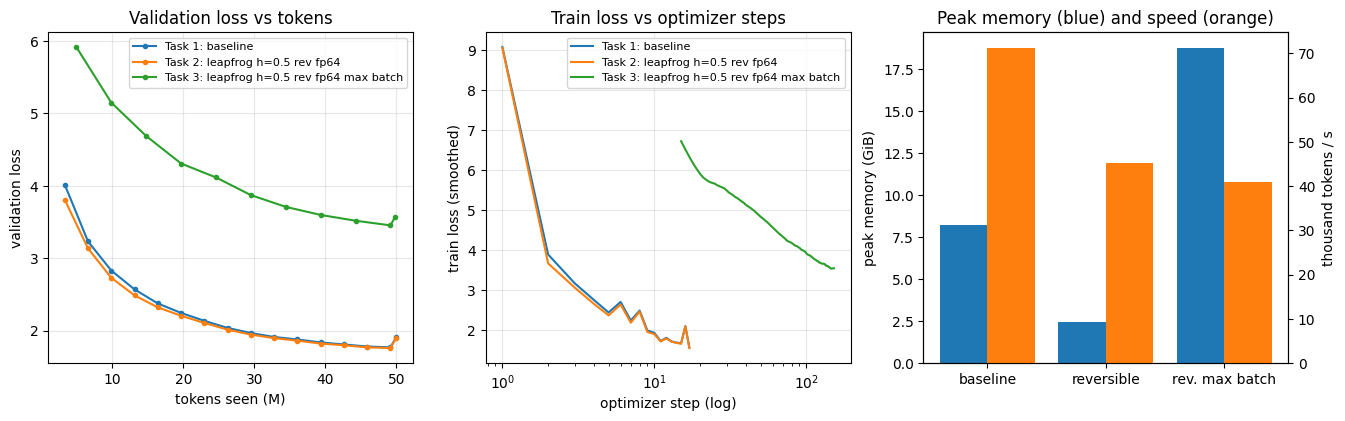

In [8]:
runs = [("Task 1: baseline", RESULTS["baseline"]), ("Task 2: " + RESULTS["reversible"]["label"], RESULTS["reversible"]),
        ("Task 3: " + res_max["label"] + " max batch", res_max)]
fig, axs = plt.subplots(1, 3, figsize=(16, 4.3))
for name, r in runs:
    vh = np.array(r["val_hist"])
    axs[0].plot(vh[:, 1] / 1e6, vh[:, 2], "o-", ms=3, label=name)
    tr = np.array([hh[2] for hh in r["hist"]])
    k = max(1, min(25, len(tr) // 10))
    sm = np.convolve(tr, np.ones(k) / k, mode="valid")
    axs[1].plot(np.arange(len(sm)) + k, sm, label=name)
axs[0].set_xlabel("tokens seen (M)"); axs[0].set_ylabel("validation loss"); axs[0].set_title("Validation loss vs tokens")
axs[1].set_xscale("log"); axs[1].set_xlabel("optimizer step (log)"); axs[1].set_ylabel("train loss (smoothed)")
axs[1].set_title("Train loss vs optimizer steps")
lbl = ["baseline", "reversible", "rev. max batch"]
axs[2].bar(np.arange(3) - 0.2, [r["peak_gib"] for _, r in runs], 0.4, label="peak memory (GiB)")
ax2 = axs[2].twinx()
ax2.bar(np.arange(3) + 0.2, [r["tok_per_s"] / 1e3 for _, r in runs], 0.4, color="C1", label="k tokens / s")
axs[2].set_xticks(range(3)); axs[2].set_xticklabels(lbl); axs[2].set_ylabel("peak memory (GiB)"); ax2.set_ylabel("thousand tokens / s")
axs[2].set_title("Peak memory (blue) and speed (orange)")
for a in axs[:2]:
    a.grid(alpha=0.3); a.legend(fontsize=8)
savefig("three_runs")

**Observations (§9).**

* **Maximum batch on the L4:** baseline **160** sequences (81,920 tokens, peak 18.64 GiB; 192 does not fit),
  reversible **704** sequences (360,448 tokens, peak 20.69 GiB; 736 does not fit): **× 4.40**, matching the 4.06×
  activation ratio plus the smaller fixed part. My updated prediction (≈ 4×, ≈ 1,100 sequences) had the ratio right
  and the absolute number too high, because the reversible model needs 55 KiB/token, not 40.
* **Throughput falls with batch** for both models: baseline 85.4k (B 32) → 71.4k (64) → 66.2k (128) → 65.7k (160)
  tokens/s; reversible 53.5k → 45.1k → 42.5k → 42.0k → 41.5k (512) → 38.2k (704). No gain past $B = 32$; a bigger batch
  buys memory headroom only. (The cause of the decline was not isolated; cache effects at small batch are a guess.)
* **50M tokens at the maximum:** batch 640 (704 minus ≈ 5% headroom), **152 optimizer steps**, peak lr 4 × 10⁻³ (the
  $\sqrt{B}$ rule gave 4.7 × 10⁻³, capped), 15 warm-up steps. Result: validation **3.569** against 1.899 at $B = 64$
  (+1.67), train 3.553, **40,983 tokens/s** (× 0.91 of the $B = 64$ reversible run), **peak 18.76 GiB**, 19.6 min. No
  divergence.
* **Why the loss is so much worse:** the run took 152 steps instead of 1,525. After its 152 steps it is roughly where the
  $B = 64$ run was after ~150 steps (its validation loss was 3.81 at step 100 and 3.13 at step 200), even though each
  of its steps used 10× more tokens. At equal *tokens* (34.4M) it was at 3.71 against ≈ 1.87. So past a few
  tens of thousands of tokens per step, extra tokens per step bought almost nothing: this model's critical batch size
  is far below 327,680 tokens. Reversibility delivered the 4.4× batch; spending it on batch size was the wrong use for a
  20M model with a fixed 50M-token budget.
* **Figure caveat:** in the middle panel of the last figure, the Task 1 and Task 2 curves are the restored logged
  points (one per 100 steps, see Limits) and are drawn at x = 1…17 instead of at their real steps; read their
  progress from the left panel (loss vs tokens) instead. The Task 3 curve is correct.

## 10. All results

One table with every number the assignment asks for, then a compact JSON dump of all measurements (the README is
written from it).

In [9]:
print(f"{'run':44s} {'batch':>6s} {'steps':>6s} {'train loss':>10s} {'val loss':>9s} {'tok/s':>10s} {'peak GiB':>9s} {'time min':>9s}")
for name, r in runs:
    print(f"{name:44s} {r['batch']:6d} {r['steps']:6d} {r['final_train']:10.4f} {r['final_val']:9.4f} {r['tok_per_s']:10,.0f} "
          f"{r['peak_gib']:9.3f} {r['train_time_s'] / 60:9.1f}")
mbr = RESULTS["max_batch"]
print(f"\nmaximum batch that fits on the {props.name}: baseline {mbr['baseline']} sequences, reversible {mbr['reversible']} "
      f"sequences  (x{mbr['reversible'] / mbr['baseline']:.2f})")
mv = RESULTS["mem_vs_batch"]
print("activation memory per token:", ",  ".join(f"{k} {v['slope_kib']:.1f} KiB" for k, v in mv.items() if isinstance(v, dict)))

compact = {k: ({kk: vv for kk, vv in v.items() if kk not in ("hist", "val_hist", "model")} if isinstance(v, dict) and "hist" in v else v)
           for k, v in RESULTS.items() if k != "screen"}
compact["screen"] = [{kk: vv for kk, vv in r.items() if kk not in ("hist", "val_hist")} for r in RESULTS.get("screen", [])]
print("\nRESULTS_JSON " + json.dumps(compact, default=str))

run                                           batch  steps train loss  val loss      tok/s  peak GiB  time min
Task 1: baseline                                 64   1525     1.8956    1.9090     71,229     8.230      11.7
Task 2: leapfrog h=0.5 rev fp64                  64   1525     1.8863    1.8994     45,150     2.438      18.4
Task 3: leapfrog h=0.5 rev fp64 max batch       640    152     3.5526    3.5688     40,983    18.760      19.6

maximum batch that fits on the NVIDIA L4: baseline 160 sequences, reversible 704 sequences  (x4.40)
activation memory per token: baseline (Euler, stored) 224.9 KiB,  leapfrog h=0.5 fp64 (stored) 229.4 KiB,  leapfrog h=0.5 rev fp64 55.4 KiB

RESULTS_JSON {"baseline": {"label": "euler", "batch": 64, "seq": 512, "tokens_per_step": 32768, "steps": 1525, "planned_steps": 1525, "lr": 0.0015, "warmup_steps": 30, "final_train": 1.8956, "final_val": 1.909, "tok_per_s": 71229.0, "train_time_s": 702.0, "wall_s": 714.0, "peak_gib": 8.23, "diverged": false, "rel

**Observations (§10, overall).**

| task | batch | steps | train loss | val loss | tokens/s | peak GiB | time |
|---|--:|--:|--:|--:|--:|--:|--:|
| 1. baseline (standard residual) | 64 | 1,525 | 1.8956 | 1.9090 | 71,229 | 8.230 | 11.7 min |
| 2. reversible, leapfrog $h = 0.5$ (fp64 stream) | 64 | 1,525 | 1.8863 | 1.8994 | 45,150 | 2.438 | 18.4 min |
| 3. reversible, leapfrog $h = 0.5$, max batch | 640 | 152 | 3.5526 | 3.5688 | 40,983 | 18.760 | 19.6 min |

* **Which variant worked:** leapfrog (the second-order "wave equation" rule of Gal et al.). Midpoint, the rule in the
  lesson, trained 0.3–0.5 worse at 5M tokens in this setup; Hamiltonian was in between.
* **What reversibility costs and buys here:** same loss, 0.63× the speed (≈ 0.77× from the recompute, the rest from the
  fp64 stream), 3.4× less peak memory at the same batch, 4.1× less activation memory per token, 4.4× larger maximum
  batch, and activation memory that does not grow with depth (31 vs 368 MiB per layer).
* **The finding I did not expect:** reversibility only works if the backward pass reproduces the forward *bit for bit*.
  With bf16 matrix products and an fp32 stream, rounding flips amplified the rebuild error to 191% and the gradient
  error to 18–92%, and that cost 0.07–0.23 of loss at 5M tokens. An fp64 stream (or a well-scaled fp32 stream)
  removes the problem.
* **Spending the memory on batch size was the wrong choice** at this scale: 10× fewer updates cost 1.67 in loss. The
  headroom is worth more as depth (12× flatter memory per layer), longer context, or a smaller GPU.

## Limits of this work

* **One seed per configuration.** The Task 2 margin (−0.0096) is within what a second seed could change; the
  screening margins (0.18–0.54) are large enough to trust the ranking, but the winner was chosen at 5M tokens only.
* **Hyper-parameters were not tuned per variant.** Every run used peak lr 1.5 × 10⁻³ and the same schedule; midpoint
  might do better with its own learning rate or $h$. The max-batch learning rate (4 × 10⁻³) came from a capped
  $\sqrt{B}$ rule, not a sweep.
* **Memory figures** come from `max_memory_allocated` in 2-step probes on random tokens (the maximum-batch search has a
  resolution of 32 sequences). The 50M run used 640, not the 704 that fit, to leave headroom.
* **Speed** is without `torch.compile`, at 5–9% MFU, on an L4 whose fp64 units are slow; the fp64 stream's cost would
  be smaller on an H100 (not measured). The ≈ 0.77× recompute cost is inferred from two different runs at $B = 64$.
* **The fp32 + scaled-embedding alternative** was only checked with a gradient check at initialisation, not trained.
  The rounding-flip mechanism is supported by the sensitivity measurement (10⁻⁷ → 3.75 × 10⁻³), not traced element by
  element.
* **Vocabulary:** GPT-2 ids remapped to 8,192 (0.2% of tokens became RARE), so the losses are not comparable with
  models that use the full GPT-2 vocabulary.
* **Execution:** the runtime disconnected during the §9.3 training. §9.3 and §10 were run in a new runtime after
  re-running §0–§1 (hence their execution counts); the Task 1 and Task 2 results they plot were restored from the saved
  outputs above, so those two loss curves in the last figure have one point per 100 steps (and in its middle panel
  they are plotted against the point index, not the step).
* **Evaluation subsets:** the in-training validation points use 256 windows (131k tokens) and the final numbers 1,024
  windows (524k tokens); the subsets differ in difficulty, so only points of the same kind should be compared.


## Release the Colab runtime

The last cell disconnects the runtime so it stops consuming compute units. **After it runs, press Ctrl+S in VS Code**
so the notebook is saved with all outputs (the README and the plots are extracted from them).

In [10]:
try:
    from google.colab import runtime
    print("All done. Releasing the Colab runtime now; press Ctrl+S in VS Code to keep the outputs.")
    runtime.unassign()
except Exception as e:
    print(f"Not on Colab, or the runtime could not be released automatically ({e}); disconnect it manually.")

All done. Releasing the Colab runtime now; press Ctrl+S in VS Code to keep the outputs.
